In [2]:
from dynamic_catalysis_model import cycle_flux_fn, map_graph_weights_ten_states
import networkx as nx
import numpy as np
oscMidpoint = 0
k_bT = 1
dG_1 = 3
dG_2 = 1

dG_1_w = 2
dG_2_w = 2
epsilon = 0

alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 2e9
N = 10
G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
G.add_edges_from([(0, 1), (1, 2), (0,2), (2, 3), (3, 4), (4,2), (5, 6), (6, 7), (5, 7), (7, 8), (8, 9), (9, 7), (0, 5), (1, 6), (2, 7), (3, 8), (4, 9)])
node_indices = list(range(N))
spanTreesGraph = [i for i in nx.SpanningTreeIterator(G)]
epsilon_list = np.linspace(-15,15,100)
J_tot_list_cycle_r = []
J_tot_list_cycle_w = []

def max_rate_dummy(**params):
    return 1

for epsilon in epsilon_list:
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e-11
    alpha_41 = 1e-11
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    futile_cycles = [[0,5], [1,6], [2,7], [3,8], [4,9]]
    J_tot_r, J_tot_w = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=max_rate_dummy, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    J_tot_list_cycle_r.append(J_tot_r * max_rate_dummy())
    J_tot_list_cycle_w.append(J_tot_w * max_rate_dummy())



<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:12: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1701/577447347.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: F

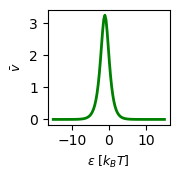

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(1.9,1.9))

# s3 = figure(title="Flux", x_range=(-10, 10), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
# plt.xlim(-10, 10)
# plt.ylim(0, 5)
plt.plot(epsilon_list, J_tot_list_cycle_r, color='green', label='Total Flux', linewidth=2,)
# plt.plot(epsilon_list, [J_tot_list_cycle_w[i] for i in range(len(epsilon_list))], color='red', label='Total Flux', linewidth=2, )
# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel(r'$\bar{v}$', fontsize=9, fontdict={'family': 'sans-serif'})
# plt.xticks([-10, -5, 0, 5, 10], fontsize=6)
# plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1701/2540597552.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/tmp/ipykernel_1701/2540597552.py:13: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'L

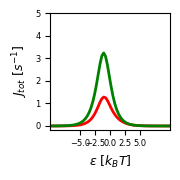

In [4]:
plt.figure(figsize=(1.9,1.9))

plt.plot(epsilon_list, [J_tot_list_cycle_r[i]/J_tot_list_cycle_w[i] for i in range(len(epsilon_list))], color='red', label='Selectivity', linewidth=2,)
plt.plot(epsilon_list, J_tot_list_cycle_r, color='green', label='Total Flux', linewidth=2,)

# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
# s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
plt.xlim(-10, 10)
# plt.ylim(0, 5)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-5, -2.5, 0, 2.5, 5], fontsize=6)
plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

In [7]:
max_steady_state = np.max(J_tot_list_cycle_r)
def get_best_steady_state(**params):
    return max_steady_state

import numpy as np
import sys, os, time
from utilsGRF import BoundaryFinder as BF

#In all the examples, this will be fixed:

#Define the grid:
stp_ar=np.arange(1e-11, 6, 0.03) #The mathematica files to check the results assume a grid spacing of 0.005. Change that if this is modified. 
pos_ar=np.arange(1, 3, 0.010)
minp=1e-3
maxp=1e3


defaultsettings={'pars_limit':[minp,maxp],
           'row_ar':stp_ar,
          'col_ar':pos_ar,
          'seed':1,
         'mat':None,
         'mat_pars':None}


defaultargs={'niters':5, #for testing purposes only 5 iterations, or it will take very long
      'niters_conv':100,
      'niters_conv_points':1000,
      'niters_save':2,
      'prob_par':0.5,
      'prob_replace':0.5,
      'extr_uniform':[-1,1],
      'L_project':10,
      'plotting':True,
      'verbose':True,
       'dofirstmutate':True,
      'dopullcentroids':True,
      'dopulltangents':True} 

0,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

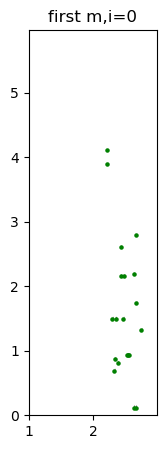

KeyboardInterrupt: 

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

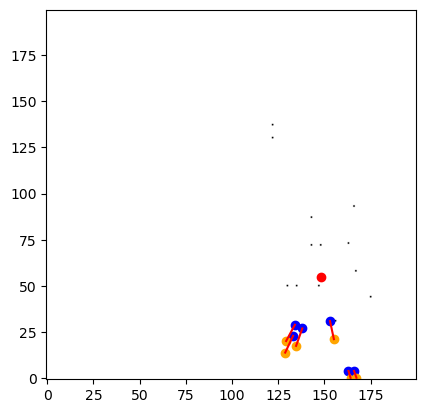

In [9]:
#code that runs the boundary exploration in the space given by the function myfN2
#set plotting:False in args dict when running for many iterations, so that no plots are shown
def rate_fn(*params):
    epsilon_midpoint = epsilon_list[np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list_cycle_r) == np.max(J_tot_list_cycle_r))[0][0]]))]
    # alpha_14, alpha_41, epsilon_1, epsilon_2 = params[0]
    # epsilon_1 = np.log10(epsilon_1)
    # epsilon_2 = np.log10(epsilon_2)
    alpha_14, alpha_41, amplitude= params[0]
    amplitude = np.log10(amplitude)
    epsilon_1 = epsilon_midpoint - amplitude
    epsilon_2 = epsilon_midpoint + amplitude
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    futile_cycles = [[0,5], [1,6], [2,7], [3,8], [4,9]]
    speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    # futile, _ = cycle_flux_fn(futile_cycles, [], G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
    #                                             alpha_21=0, alpha_54=alpha_54, alpha_65=0,\
    #                                             alpha_21_w=0, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=0, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
    #                                             gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    futile = k_bT * np.log10(alpha_14 / alpha_41)
    return selectivity, futile

outfolder="test"
if not os.path.isdir(outfolder):
    os.mkdir(outfolder)
name_save="namesave_g20000_sweep"
outfolder_final=outfolder
name='%s_last'%(name_save)


settings=defaultsettings.copy()
# constraints={1:{'target':0,'lt':1},3:{'target':2,'lt':1},5:{'target':4,'lt':1}} #the coefficients in the numerator are at most as large as the corresponding in the denominator

# settings['constraints']=constraints
settings['compute_x_y_f']=rate_fn
settings['npars']=3
# settings['mat'] = np.load(os.path.join(outfolder_final,'mat_namesave_g20000_sweep_6.npy'))
# settings['mat_pars'] = np.load(os.path.join(outfolder_final,'mat_pars_namesave_g20000_sweep_6.npy'))

#Initialise and get first 10 points

BE=BF.BoundaryExplorer(**settings)
BE.get_initial_points(10)

#Extend boundary

args=defaultargs.copy()
args["niters"]=20 #just for testing purposes
args['folder_save']=outfolder
args['name_save']=name_save
BE.extend_boundary(**args)


np.save(os.path.join(outfolder_final,'mat_'+name+'.npy'),BE.mat)
np.save(os.path.join(outfolder_final,'mat_pars_'+name+'.npy'),BE.mat_pars)

In [10]:
pts = []
dG_1 = 3
dG_2 = 1

dG_1_w = 2
dG_2_w = 2
# BE = pkl.load(open('BE_kpr.pkl', 'rb'))
# pkl.dump(BE, open(os.path.join(outfolder_final,'BE_kpr'+name+'.pkl'), 'wb'))
BE_kpr = pkl.load(open(os.path.join(outfolder_final,'BE_kpr'+name+'.pkl'), 'rb'))
BE_dycat = pkl.load(open(os.path.join(outfolder_final,'BE_dycat'+name+'.pkl'), 'rb'))
for _ in [BE_kpr, BE_dycat]:
    for x in _.mat_pars:
        for y in x:
            # alpha_14, alpha_41, epsilon_1, epsilon_2= y
            # epsilon_1 = np.log10(epsilon_1)
            # epsilon_2 = np.log10(epsilon_2)
            alpha_14, alpha_41, amplitude= y
            amplitude = np.log10(amplitude)
            epsilon_midpoint = epsilon_list[np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list_cycle_r) == np.max(J_tot_list_cycle_r))[0][0]]))]
            epsilon_1 = epsilon_midpoint - amplitude
            epsilon_2 = epsilon_midpoint + amplitude
            right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
            wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
            futile_cycles = [[0,5], [1,6], [2,7], [3,8], [4,9]]
            # futile_cycles = [[0, 5, 6, 1], [0, 1, 6, 5], [1, 2, 7, 6], [1, 6, 7, 2], [2, 3, 8, 7], [2, 7, 8, 3], [3, 4, 9, 8], [3, 8, 9, 4]]

            speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                            alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                            alpha_21_w=alpha_65, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                            gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
            futile, _ = cycle_flux_fn(futile_cycles, [], G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                        alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                        alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                        gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
            
            # futile = k_bT * np.log10(alpha_14 / alpha_41)
            dW = k_bT * np.log10(alpha_14 / alpha_41)
            # if selectivity > 2.7:
            #     print(f"alpha_14: {alpha_14}, alpha_41: {alpha_41}, epsilon_1: {epsilon_1}, epsilon_2: {epsilon_2}, speed: {speed}, futile: {futile}, selectivity: {selectivity}")
            # else:
            #     continue
            pts.append([speed, futile, selectivity, dW])

/tmp/ipykernel_1701/4252582673.py:18: RuntimeWarning: divide by zero encountered in log10
  amplitude = np.log10(amplitude)
/home/wamesjang/anaconda3/envs/dynamic_metabolism/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2383: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow/lib/dynamic_catalysis_model.py:233: RuntimeWarning: invalid value encountered in scalar multiply
  cycle_coefficient *= edge_weight
/home/wamesjang/rockefeller/diagram_dynamic_metabolism_v2/workflow/lib/dynamic_catalysis_model.py:298: RuntimeWarning: invalid value encountered in scalar multiply
  cycle_flux = (cycle_coefficient(cycle, graph_weights) * cycle_inflows(cycle, reaction_graph, graph_weights, absorption_edge_list=absorption_edge_list)) / partition_function
/tmp/ipykernel_1701/4252582673.py:37: RuntimeWarning: invalid value encountered in scalar divide
  dW = k_bT * np.log10(alpha_14 / a

(200, 200, 80000)

/tmp/ipykernel_1701/2984376299.py:25: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter([pt[2] for pt in new_pts], [pt[0] for pt in new_pts], color='gray', cmap=plt.cm.cividis, s=10)
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found

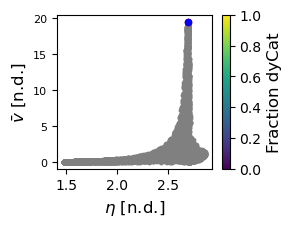

In [ ]:
# amplitude = 3



# plt.figure(figsize=(2.5,2))
# alpha_14 = 1e3
# alpha_41 = 1e-3
# epsilon_1 = epsilon_midpoint - amplitude
# epsilon_2 = epsilon_midpoint + amplitude


# speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
#                                                         alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
#                                                         alpha_21_w=alpha_65, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
#                                                         gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
# futile, _ = cycle_flux_fn(futile_cycles, [], G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
#                                             alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
#                                             alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
#                                             gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
# plt.scatter(selectivity, speed, c='red', s=20)

# pts = pkl.load(open(os.path.join(outfolder_final,'pts_selectivity'+name+'.pkl'), 'rb'))
new_pts = pts[40000:] + pts[:40000]
plt.figure(figsize=(2.5,2))
plt.scatter([pt[2] for pt in new_pts], [pt[0] for pt in new_pts], color='gray', cmap=plt.cm.cividis, s=10)
amplitude_dycat = -3
alpha_14_dycat = 1000
alpha_41_dycat = 1000
epsilon_1 = epsilon_midpoint - amplitude
epsilon_2 = epsilon_midpoint + amplitude


speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                        alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                        alpha_21_w=alpha_65, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                        gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14_dycat, alpha_41=alpha_41_dycat)
futile, _ = cycle_flux_fn(futile_cycles, [], G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                            alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                            alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                            gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14_dycat, alpha_41=alpha_41_dycat)



plt.scatter(selectivity, speed, c='red', s=20)

amplitude_kpr = -3
alpha_14_kpr = 1000
alpha_41_kpr = 1e-3
epsilon_1 = epsilon_midpoint - amplitude
epsilon_2 = epsilon_midpoint + amplitude


speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                        alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                        alpha_21_w=alpha_65, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                        gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14_kpr, alpha_41=alpha_41_kpr)
futile, _ = cycle_flux_fn(futile_cycles, [], G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                            alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                            alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                            gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14_kpr, alpha_41=alpha_41_kpr)



plt.scatter(selectivity, speed, c='blue', s=20)

x = np.linspace(0, 1, 100)
amplitude_interp = amplitude_kpr + (amplitude_dycat - amplitude_kpr) * x
alpha_14_interp = alpha_14_kpr + (alpha_14_dycat - alpha_14_kpr) * x
alpha_41_interp = alpha_41_kpr + (alpha_41_dycat - alpha_41_kpr) * x
speed_interp = []
selectivity_interp = []
for i in range(len(x)):
    epsilon_1 = epsilon_midpoint - amplitude_interp[i]
    epsilon_2 = epsilon_midpoint + amplitude_interp[i]
    speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                        alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                        alpha_21_w=alpha_65, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                        gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14_interp[i], alpha_41=alpha_41_interp[i])
    speed_interp.append(speed)
    selectivity_interp.append(selectivity)

# plt.scatter(selectivity_interp, speed_interp, cmap='RdBu')

# cbar = plt.colorbar(norm=plt.Normalize(vmin=np.min([pt[3] for pt in new_pts]), vmax=np.max([pt[3] for pt in new_pts])))
cbar = plt.colorbar(norm=plt.Normalize(vmin=np.min(x), vmax=np.max(x)))
cbar.set_label(label=r'Fraction dyCat', fontsize=12)
plt.xlabel(r'$\eta$ [n.d.]', fontsize=12, fontdict={'family': 'sans-serif'})
plt.ylabel(r'$\bar{v}$ [n.d.]', fontsize=12, fontdict={'family': 'sans-serif'})
# plt.ylim(0,2)
# plt.xticks(np.linspace(0, 150, 6), fontsize=8)
plt.yticks(fontsize=8)
plt.savefig(os.path.join(outfolder_final,'KPr_dyCat_model'+name+'.svg'), bbox_inches='tight')






In [22]:
new_pts[indices]

TypeError: only integer scalar arrays can be converted to a scalar index

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

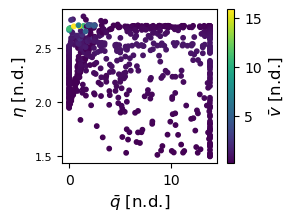

In [179]:
plt.figure(figsize=(2.5,2))
# pts = pkl.load(open(os.path.join(outfolder_final,'pts_selectivity'+name+'.pkl'), 'rb'))
plt.scatter([pt[1] for pt in pts], [pt[2] for pt in pts], c=[pt[0] for pt in pts], cmap=plt.cm.viridis, s=10)
cbar = plt.colorbar()
cbar.set_label(label=r'$\bar{v}$ [n.d.]', fontsize=12)
plt.ylabel(r'$\eta$ [n.d.]', fontsize=12, fontdict={'family': 'sans-serif'})
plt.xlabel(r'$\bar{q}$ [n.d.]', fontsize=12, fontdict={'family': 'sans-serif'})
# plt.xticks(np.linspace(0, 150, 6), fontsize=8)
# plt.ylim(0,2)
plt.yticks(fontsize=8)
plt.savefig(os.path.join(outfolder_final,'selectivity_vs_speed_vs_futile_ctrl_2'+name+'.png'), dpi=300, bbox_inches='tight')


findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

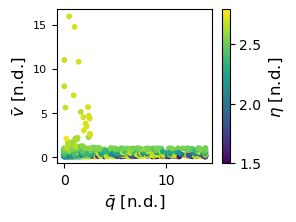

In [180]:
plt.figure(figsize=(2.5,2))
# pts = pkl.load(open(os.path.join(outfolder_final,'pts_selectivity'+name+'.pkl'), 'rb'))
plt.scatter([pt[1] for pt in pts], [pt[0] for pt in pts], c=[pt[2] for pt in pts], cmap=plt.cm.viridis, s=10)
cbar = plt.colorbar(norm=plt.Normalize(vmin=0, vmax=2))
# cbar.set_clim(vmin=-1, vmax=2)
cbar.set_label(label=r'$\eta$ [n.d.]', fontsize=12)
plt.ylabel(r'$\bar{v}$ [n.d.]', fontsize=12, fontdict={'family': 'sans-serif'})
plt.xlabel(r'$\bar{q}$ [n.d.]', fontsize=12, fontdict={'family': 'sans-serif'})
# plt.xticks(np.linspace(0, 150, 6), fontsize=8)
# plt.ylim(0,2)
plt.yticks(fontsize=8)
plt.savefig(os.path.join(outfolder_final,'selectivity_vs_speed_vs_futile_ctrl_2'+name+'.png'), dpi=300, bbox_inches='tight')


In [52]:
print([i[2] for i in pts])

[np.float64(0.9999999999999931), np.float64(1.0), np.float64(0.9999999999999969), np.float64(1.0), np.float64(0.9999999999999997), np.float64(1.0000000000000004), np.float64(0.9999999999999984), np.float64(1.0), np.float64(0.9999999999999932), np.float64(1.0000000000000018), np.float64(0.999999999999994), np.float64(1.0), np.float64(0.9999999999999932), np.float64(1.0), np.float64(0.9999999999999933), np.float64(1.0), np.float64(0.9999999999999957), np.float64(1.0), np.float64(0.9999999999999936), np.float64(1.0), np.float64(0.9999999999999933), np.float64(1.0), np.float64(0.9999999999999941), np.float64(1.0), np.float64(0.9999999999999972), np.float64(1.0), np.float64(0.9999999999999993), np.float64(1.0), np.float64(0.9999999999999991), np.float64(1.0), np.float64(0.9999999999999929), np.float64(1.0000000000000009), np.float64(0.999999999999993), np.float64(1.0000000000000062), np.float64(0.9999999999999998), np.float64(1.0), np.float64(0.9999999999999929), np.float64(1.00000000000000

Text(0, 0.5, 'Speed')

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

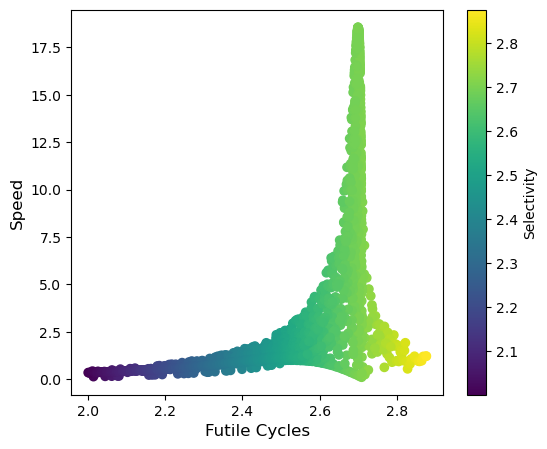

In [ ]:
fig, ax = plt.subplots(figsize=(6,5))
pkl.dump(pts, open(os.path.join(outfolder_final,'pts_selectivity'+name+'.pkl'), 'wb'))
plt.scatter([pt[1] for pt in pts], [pt[0] for pt in pts], c=[pt[2] for pt in pts], cmap=plt.cm.viridis)
plt.colorbar(label='Selectivity')
plt.xlabel('Futile Cycles', fontsize=12, fontdict={'family': 'sans-serif'})
plt.ylabel('Speed', fontsize=12, fontdict={'family': 'sans-serif'})

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

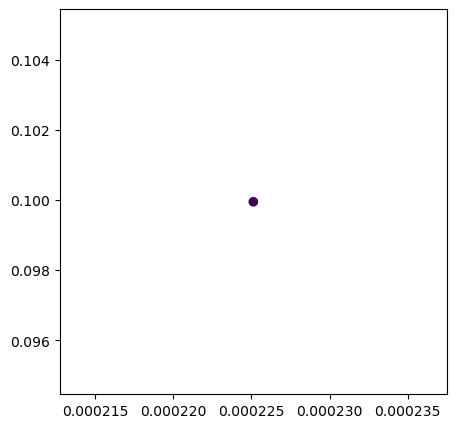

In [26]:
plt.figure(figsize=(5,5))
plt.scatter([pt[1] for pt in pts], [pt[0] for pt in pts], c=[pt[2] for pt in pts], cmap=plt.cm.viridis)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

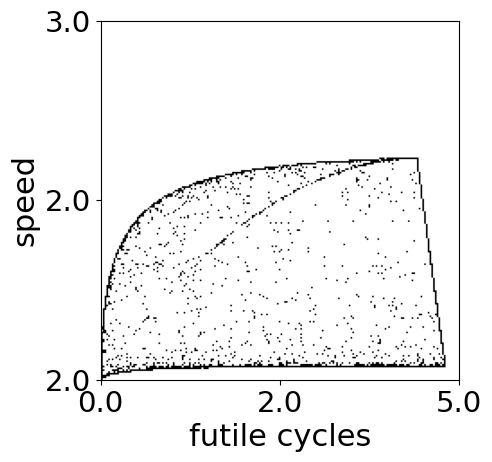

In [18]:
# start coding here
import matplotlib.pyplot as plt
import pickle as pkl
import numpy as np
pkl.dump(BE, open('BE_kpr.pkl', 'wb'))
plt.rcParams['text.usetex'] = False
plt.subplots(figsize=(5,5))
# with open(snakemake.input[0], 'rb') as handle:
#     BE = pickle.load(handle)
plt.imshow(BE.mat.T,origin='lower',extent=[1e-11,200,1e-11,200],cmap=plt.cm.Greys)
# plt.title('The dynamic speed-energy tradeoff')
# plt.ylabel(r'energy efficiency $\eta$ [n.d.]')
# plt.xlabel(r'$\bar{q}$ [n.d.]', fontdict={'size': 36})
plt.xlabel(r'futile cycles', fontdict={'size': 22})
plt.ylabel(r'speed', fontdict={'size': 22})

# plt.ylabel(r'$\bar{v}$ [n.d.]', fontdict={'size': 36})
# plt.xticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,20,3), 0), fontdict={'size': 24})
# plt.yticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,20,3), 0), fontdict={'size': 24})
plt.xticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,5,3), 0), fontdict={'size': 21})
plt.yticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(2,3,3), 0), fontdict={'size': 21})
# plt.scatter(np.argmin(np.abs(np.arange(0,80, 0.4) - 14.178257380895348)), np.argmin(np.abs(np.arange(0,10, 0.05) - 9.491175296966782)), color='green', s=100, label='Current Point')
# plt.scatter(np.argmin(np.abs(np.arange(0,80, 0.4) - 63.966904915376169)), np.argmin(np.abs(np.arange(0,10, 0.05) - 2.224292566172458)), color='blue', s=100, label='Current Point')
# plt.scatter(np.argmin(np.abs(np.arange(0,80, 0.4) - 0.0015559854903044196)), np.argmin(np.abs(np.arange(0,10, 0.05) - 0.11947555063249195)), color='red', s=100, label='Current Point')


plt.tight_layout()
plt.savefig('output.svg', format='svg', transparent=True)
plt.show()

In [26]:
max_steady_state = np.max(J_tot_list_cycle_r)
def get_best_steady_state(**params):
    return max_steady_state

import numpy as np
import sys, os, time
from utilsGRF import BoundaryFinder as BF

#In all the examples, this will be fixed:

#Define the grid:
stp_ar=np.arange(1e-11, 5,0.025) #The mathematica files to check the results assume a grid spacing of 0.005. Change that if this is modified. 
pos_ar=np.arange(1e-11,5,0.025)

minp=1e-3
maxp=1e3


defaultsettings={'pars_limit':[minp,maxp],
           'row_ar':stp_ar,
          'col_ar':pos_ar,
          'seed':1,
         'mat':None,
         'mat_pars':None}


defaultargs={'niters':5, #for testing purposes only 5 iterations, or it will take very long
      'niters_conv':100,
      'niters_conv_points':1000,
      'niters_save':2,
      'prob_par':0.5,
      'prob_replace':0.5,
      'extr_uniform':[-1,1],
      'L_project':10,
      'plotting':True,
      'verbose':True,
       'dofirstmutate':True,
      'dopullcentroids':True,
      'dopulltangents':True} 

0,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

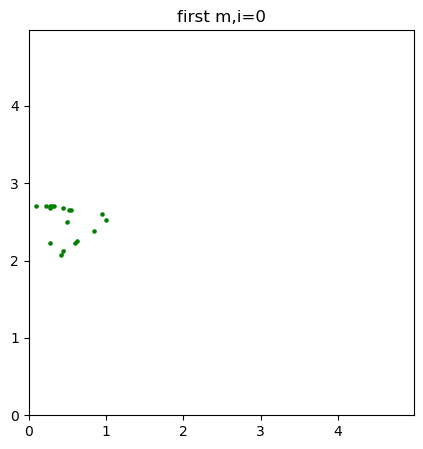

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

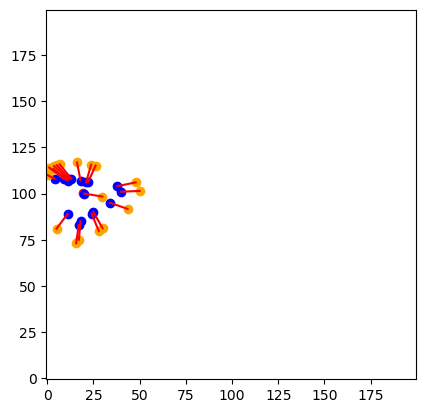

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

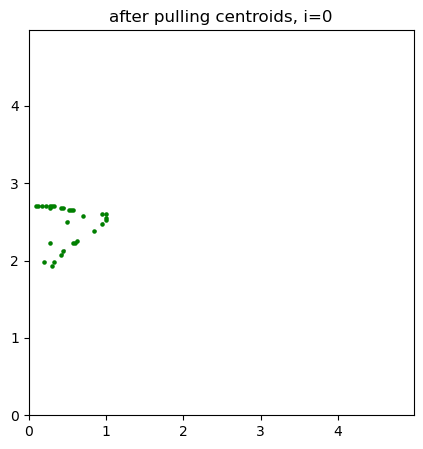

0 20.0.,1,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

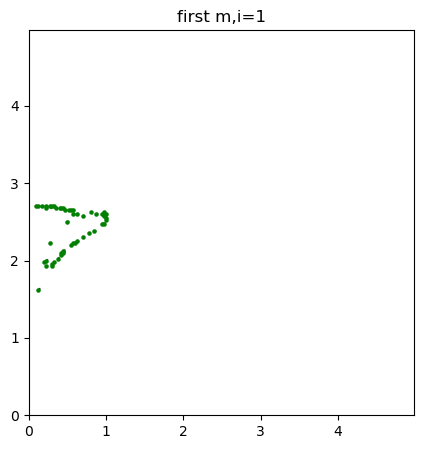

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

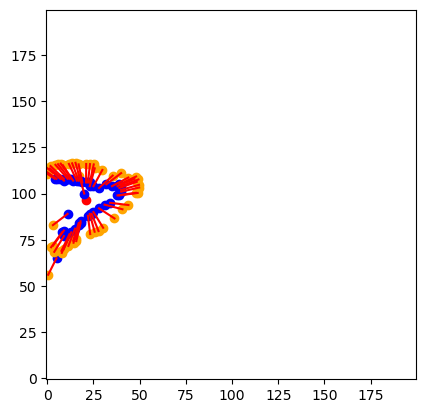

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

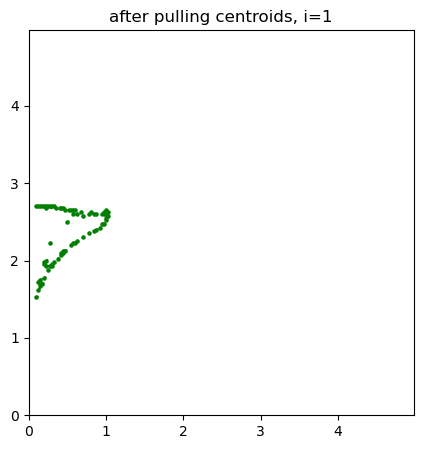

1 45.0.,2,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

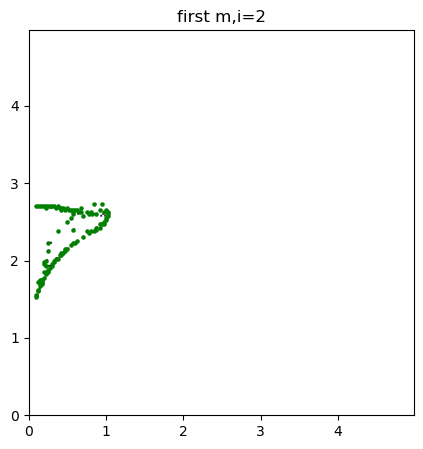

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

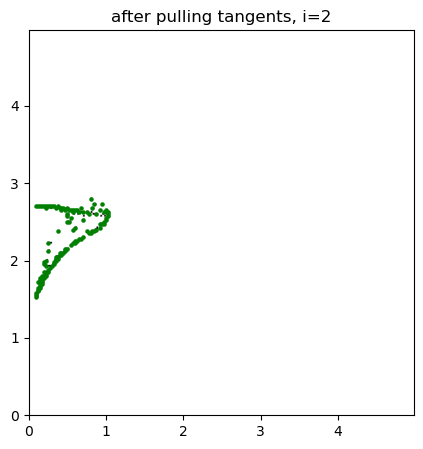

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

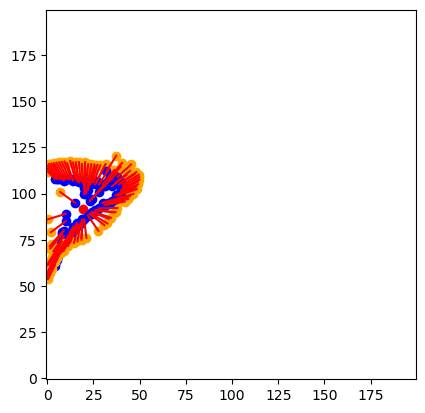

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

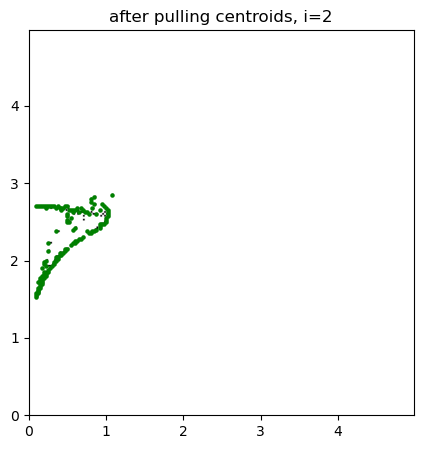

2 84.0.,3,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

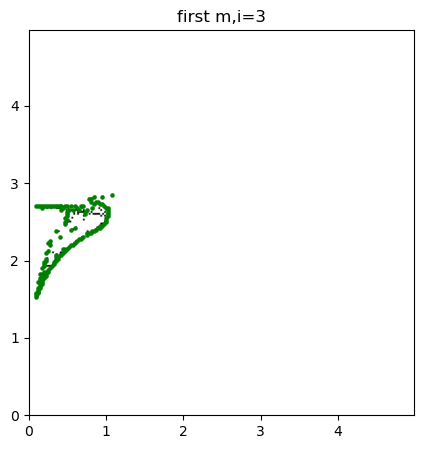

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

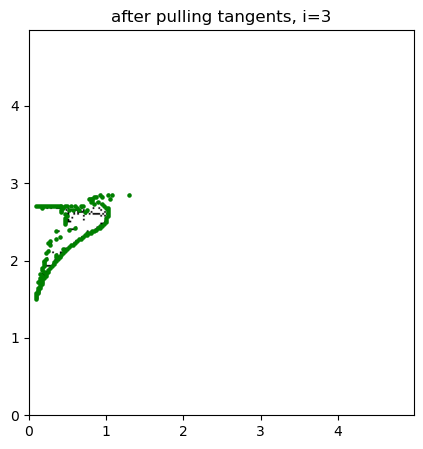

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

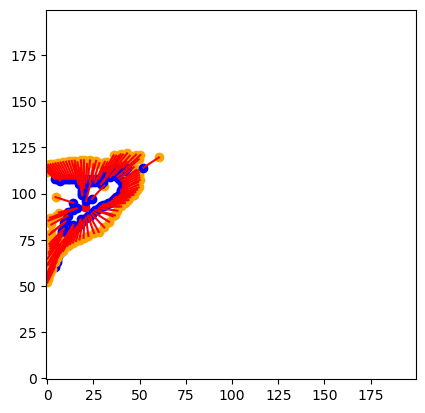

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

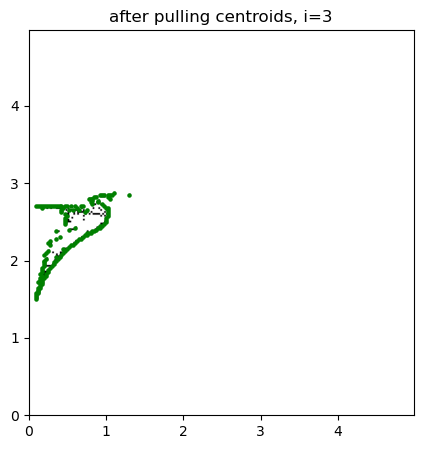

3 70.0.,4,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

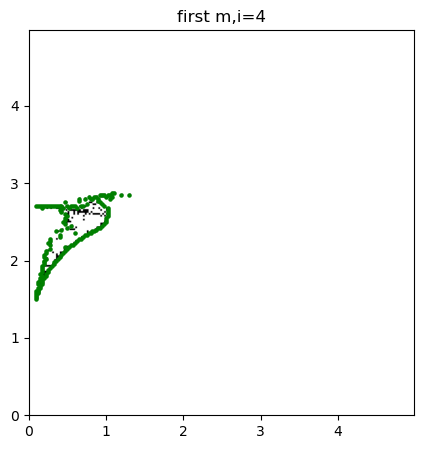

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

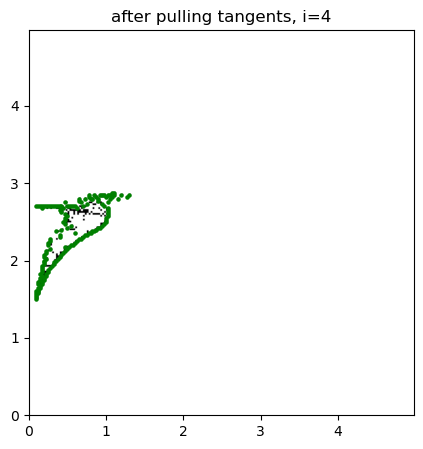

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

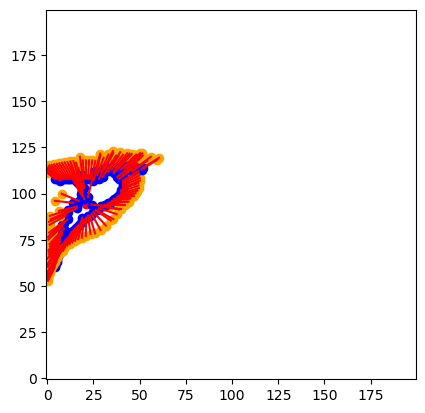

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

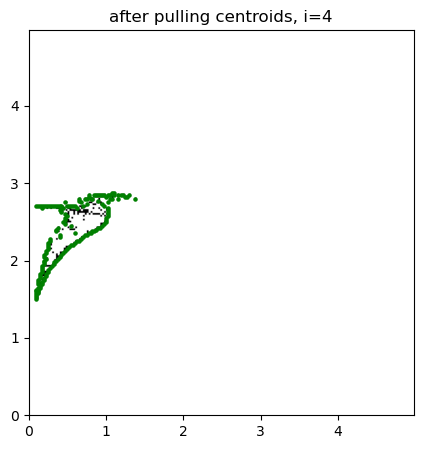

4 60.0.,5,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

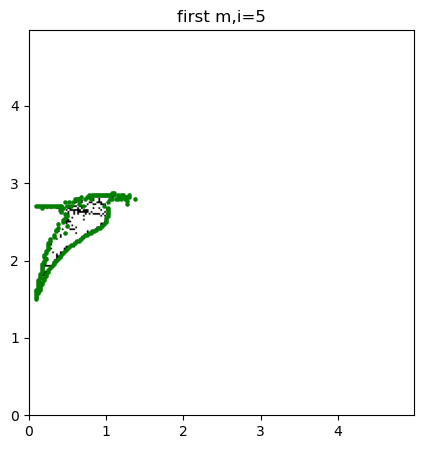

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

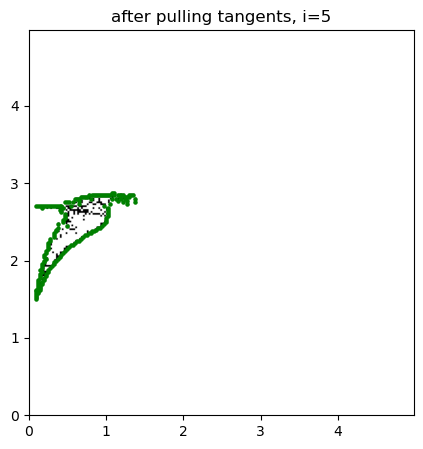

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

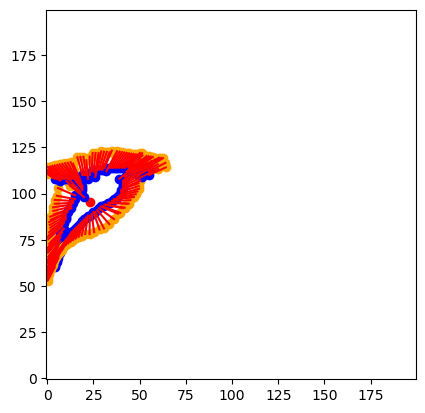

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

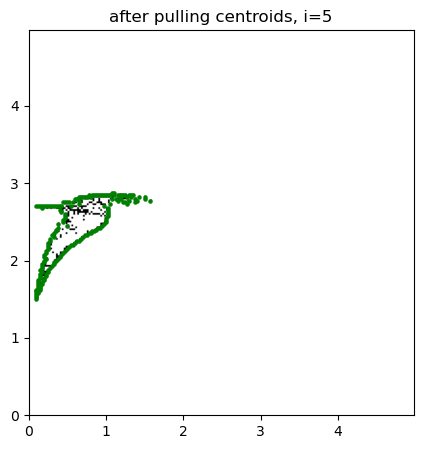

5 57.0.,6,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

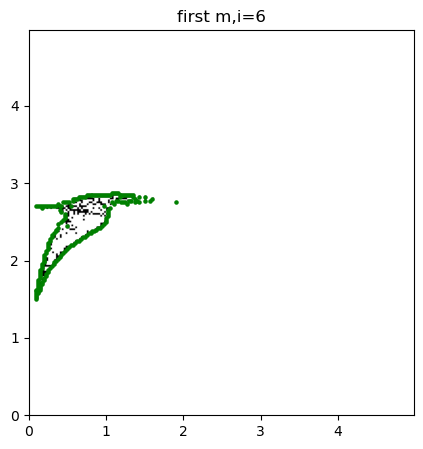

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

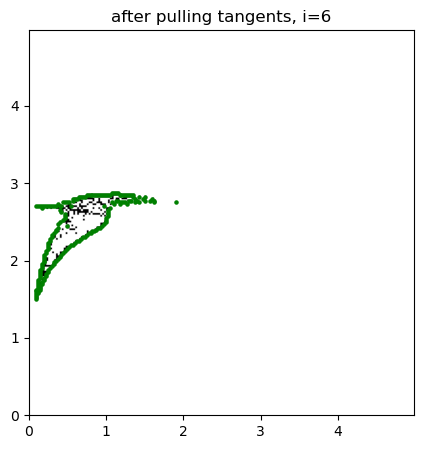

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

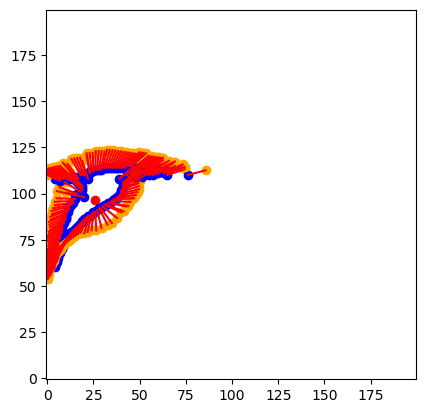

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

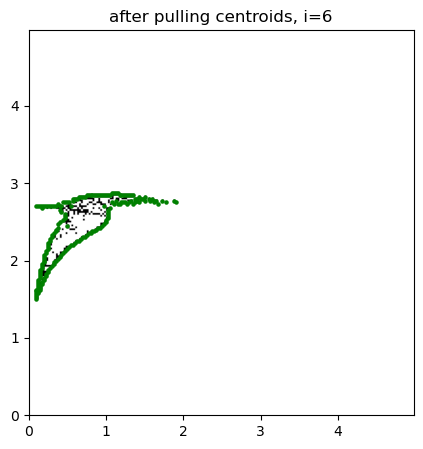

6 44.0.,7,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

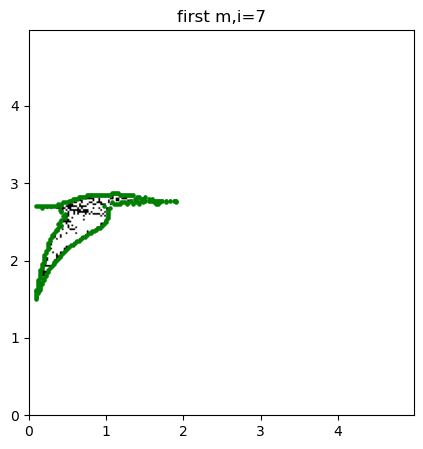

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

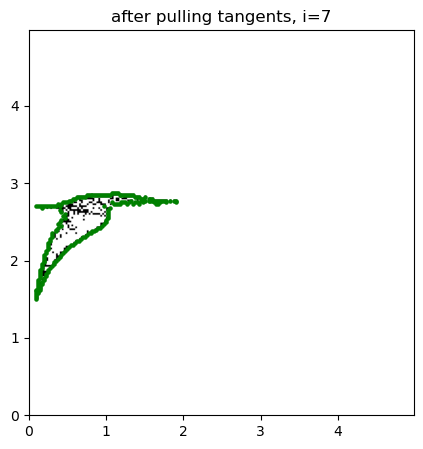

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

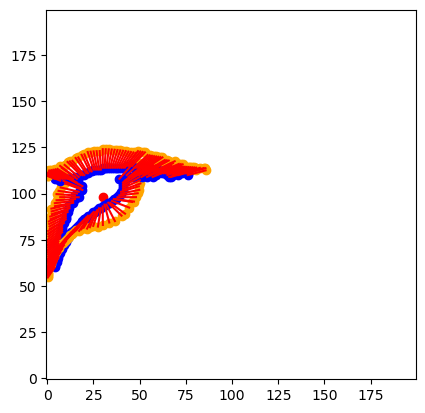

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

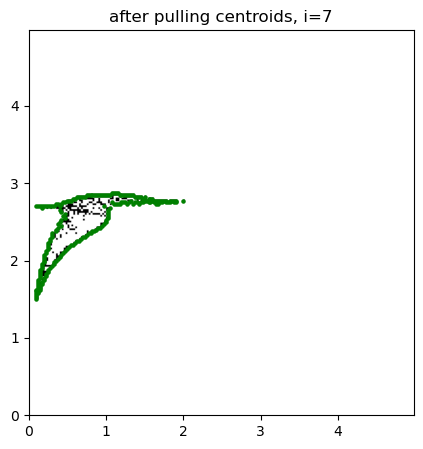

7 40.0.,8,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

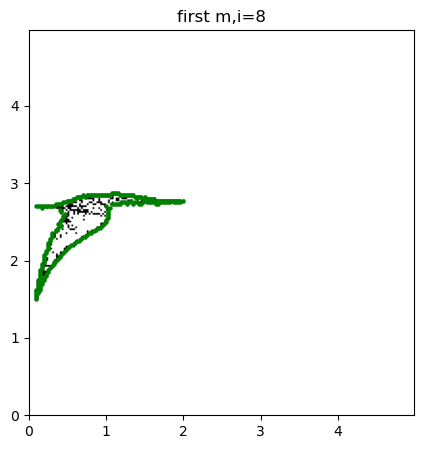

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

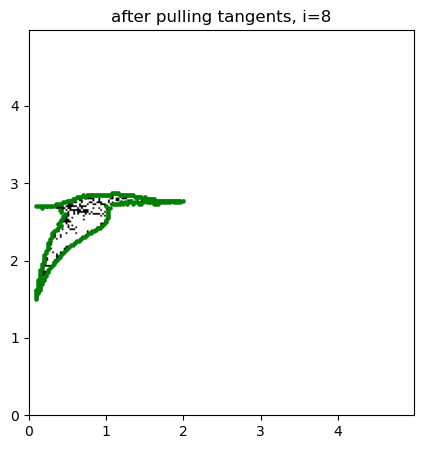

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

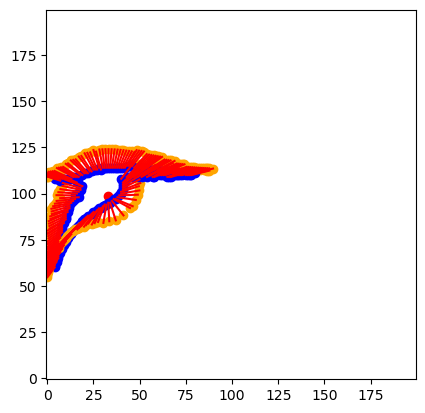

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

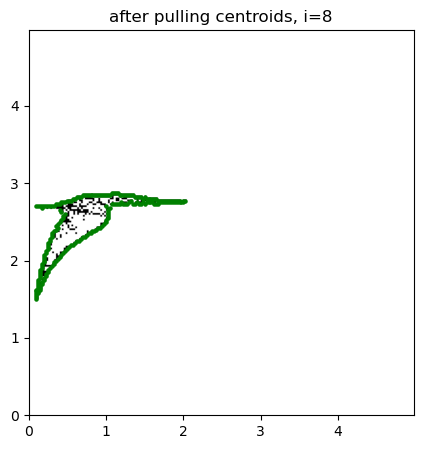

8 30.0.,9,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

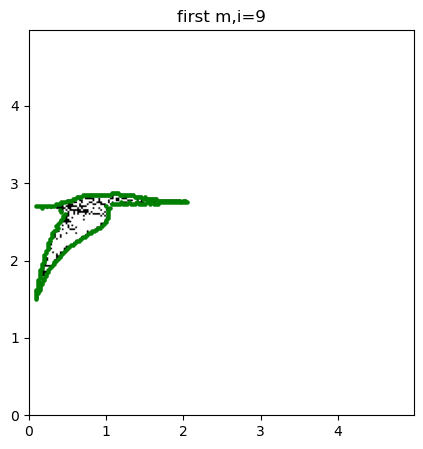

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

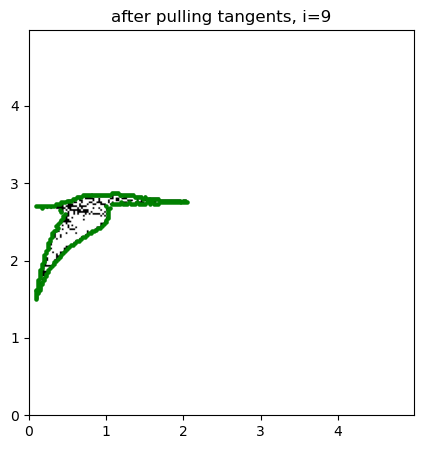

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

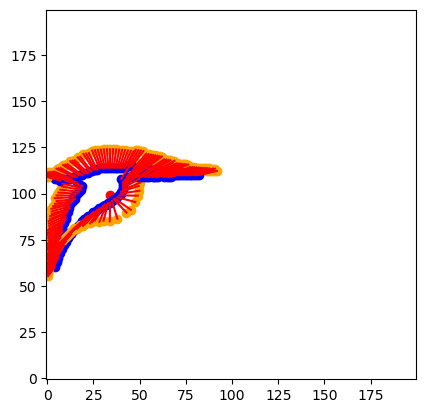

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

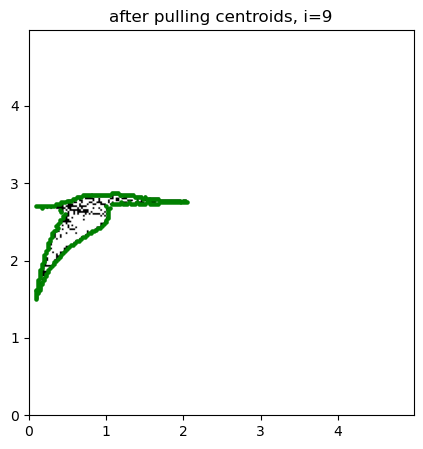

9 8.0.,10,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

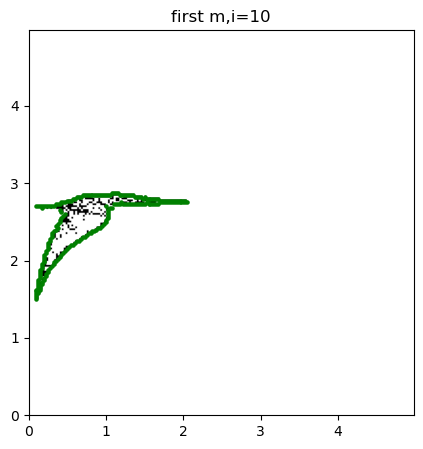

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

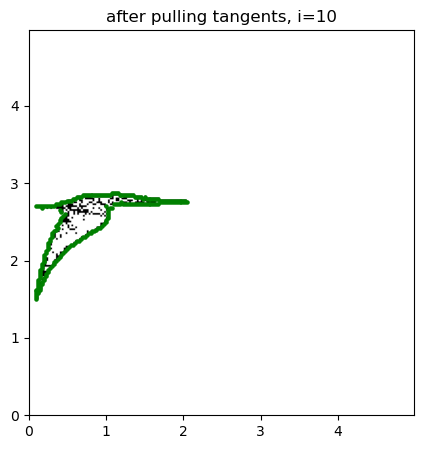

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

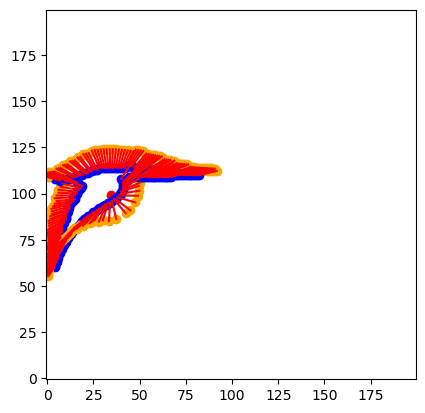

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

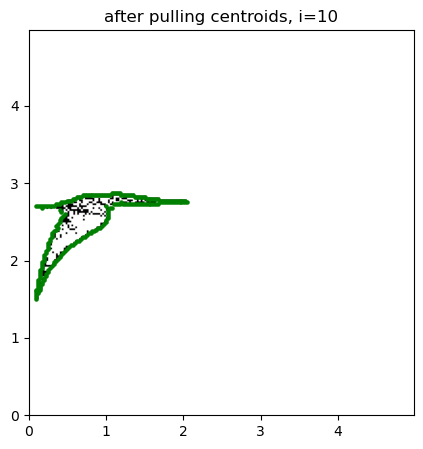

10 10.0.,11,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

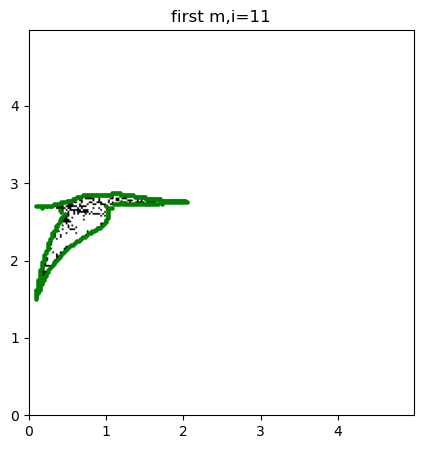

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

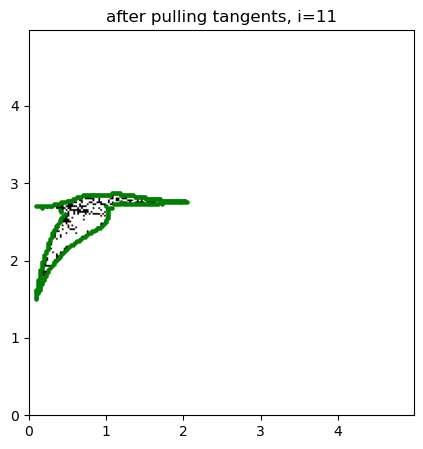

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

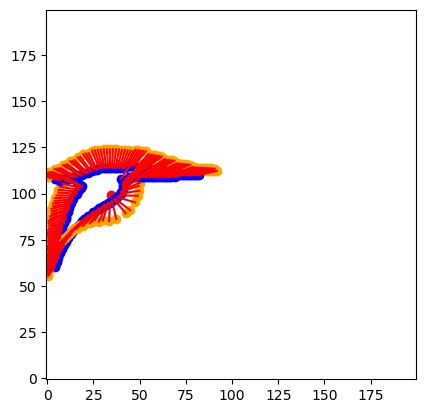

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

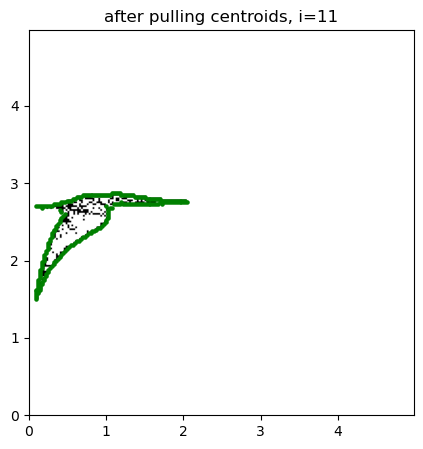

11 5.0.,12,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

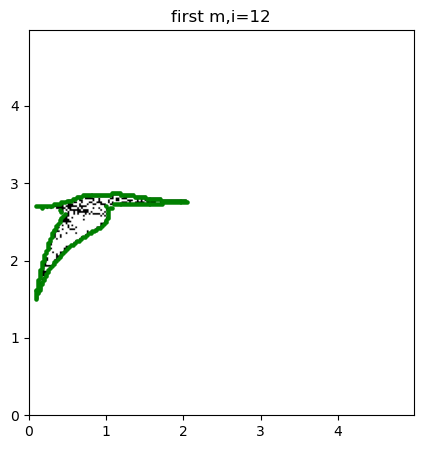

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

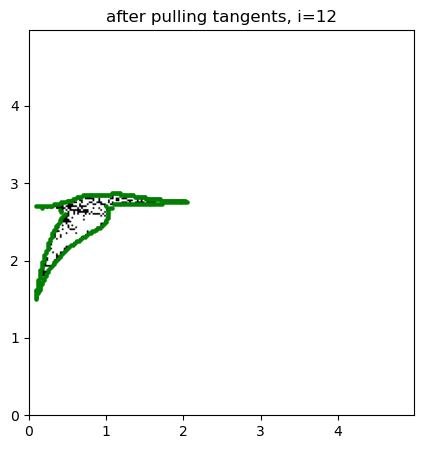

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

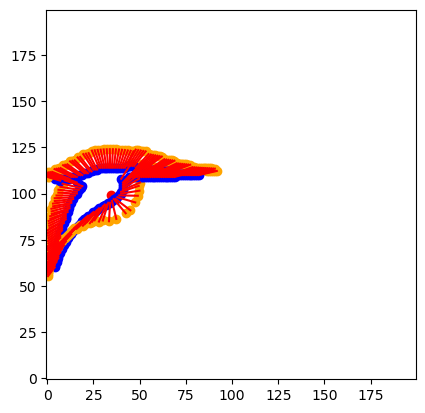

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

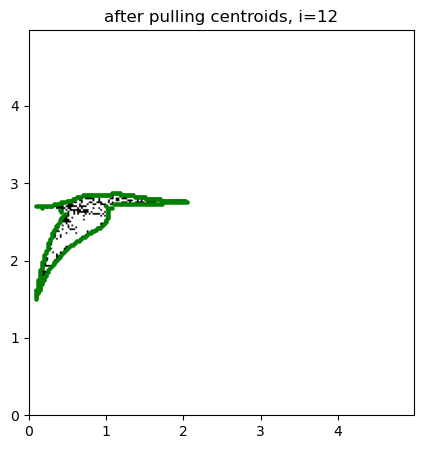

12 2.0.,13,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

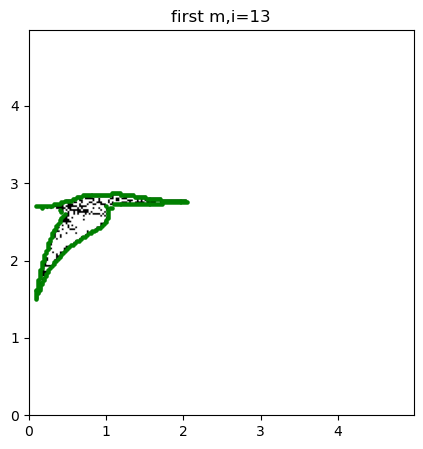

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

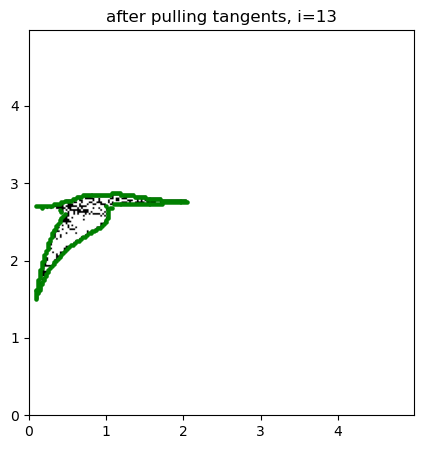

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

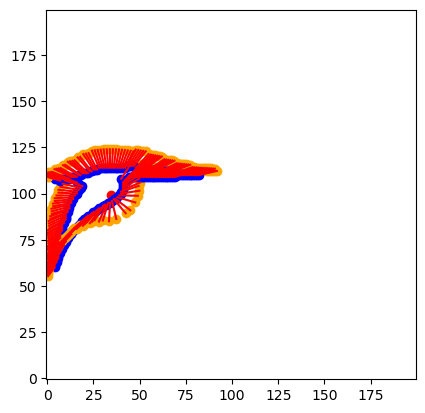

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

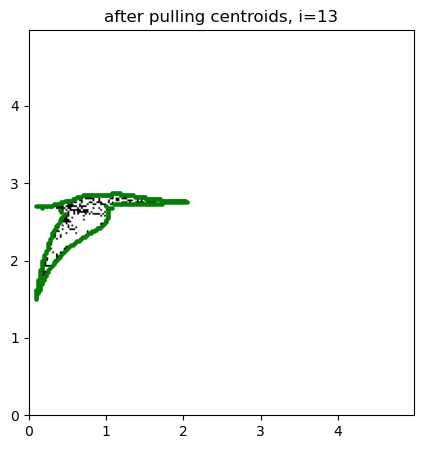

13 2.0.,14,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

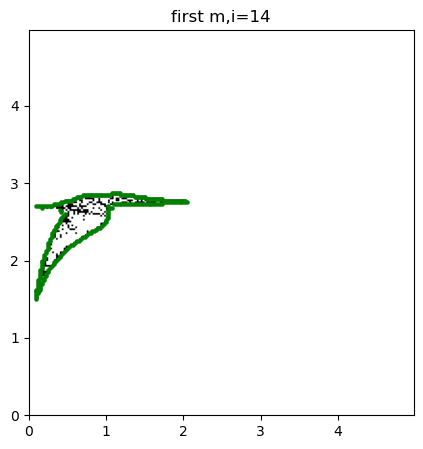

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

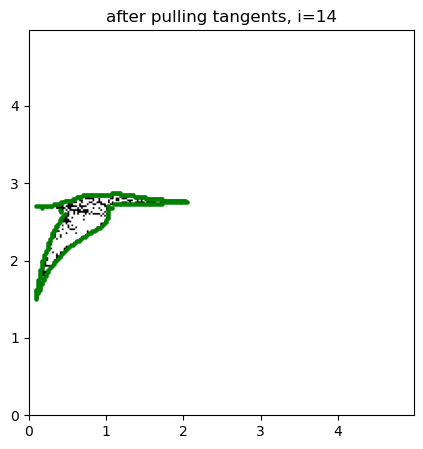

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

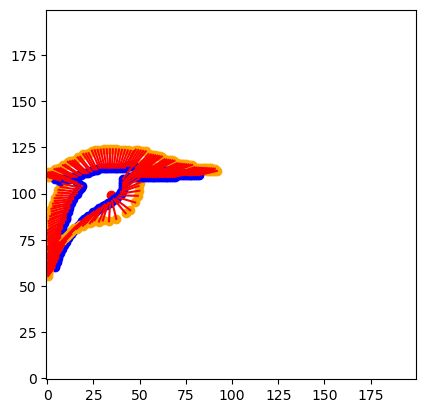

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

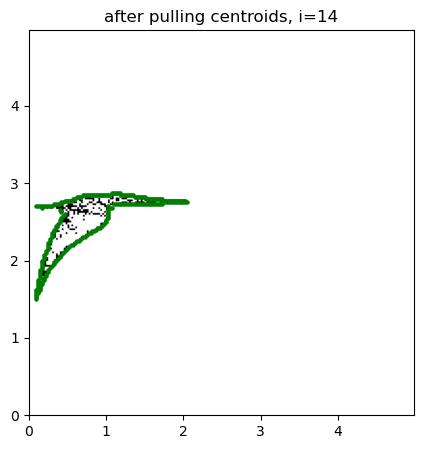

14 2.0.,15,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

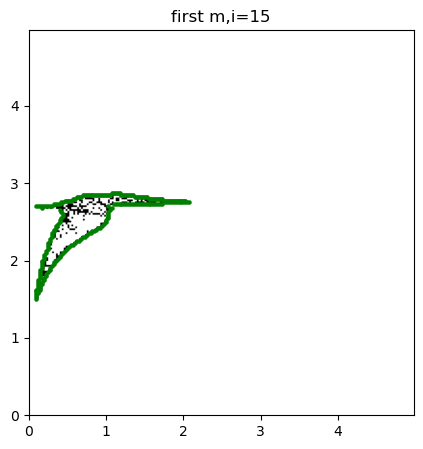

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

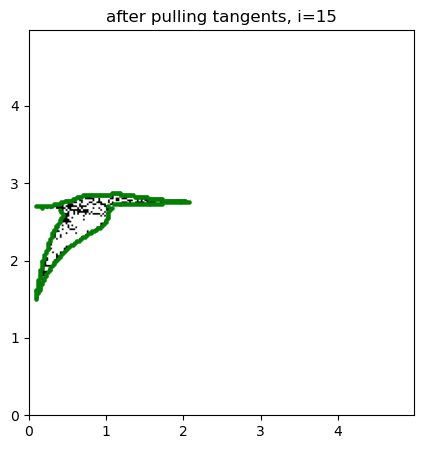

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

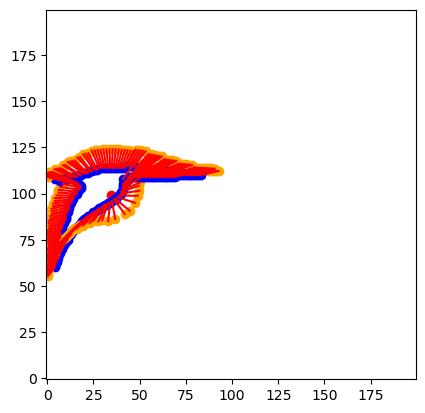

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

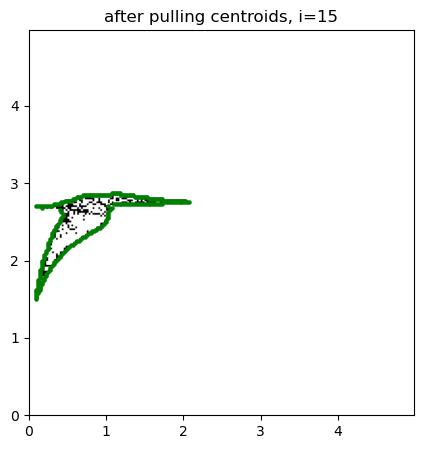

15 5.0.,16,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

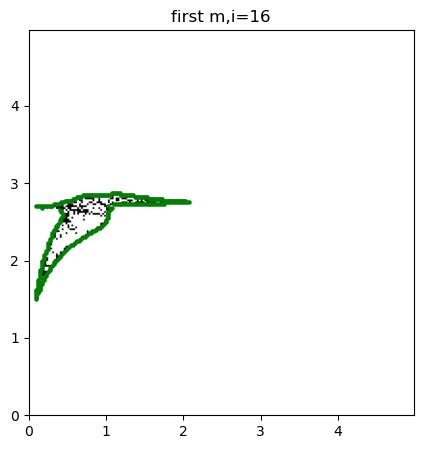

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

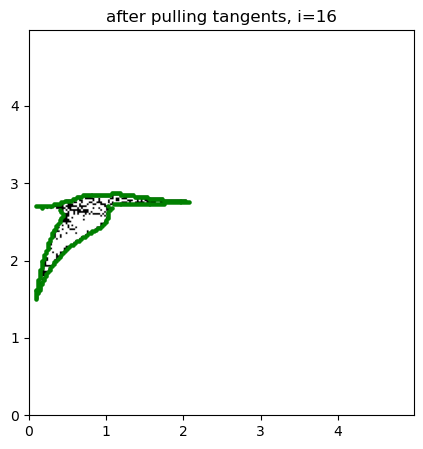

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

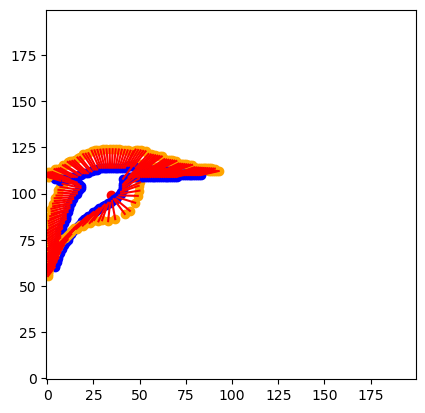

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

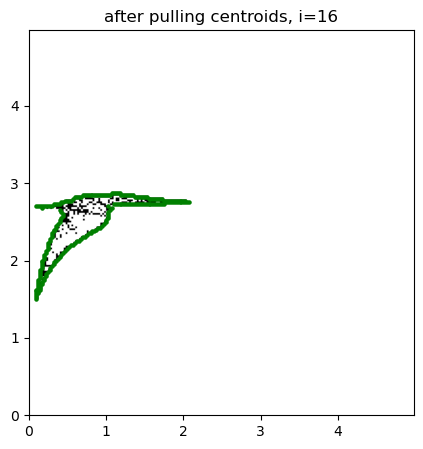

16 2.0.,17,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

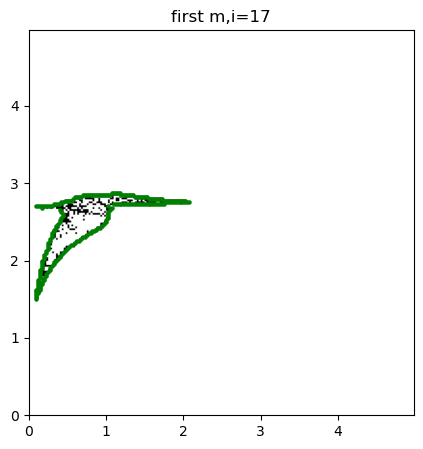

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

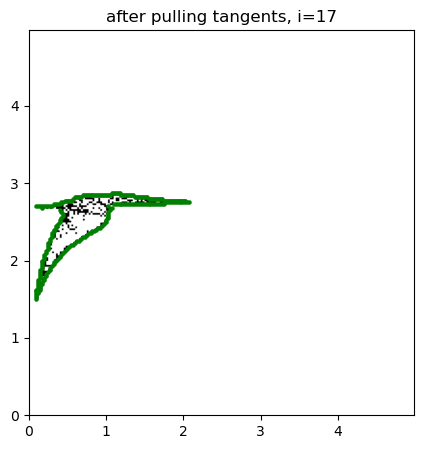

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

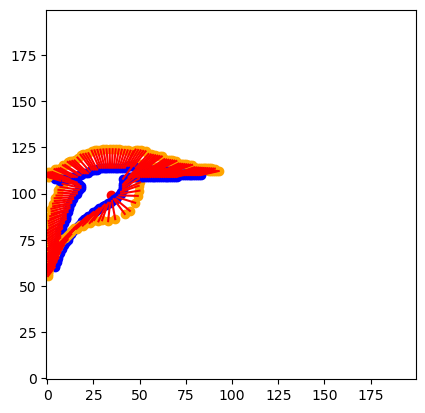

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

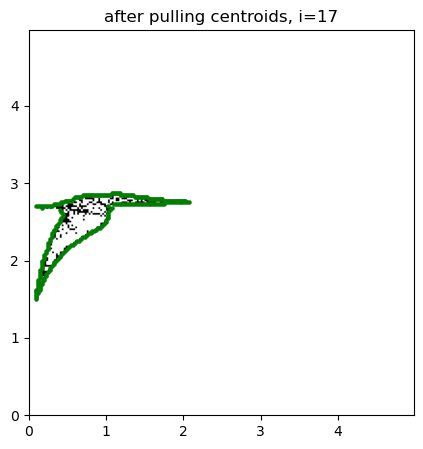

17 0.0.,18,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

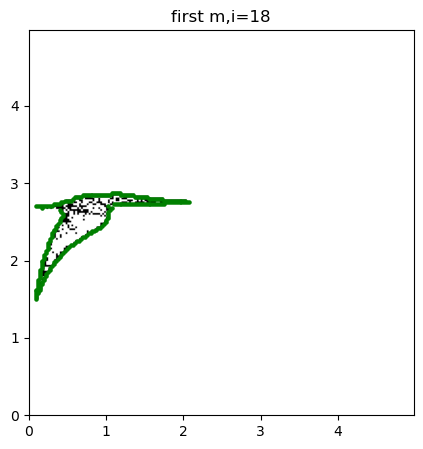

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

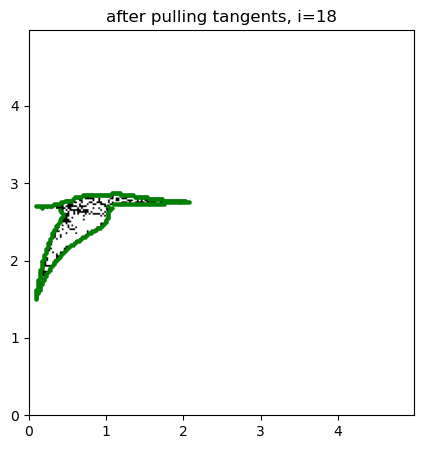

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

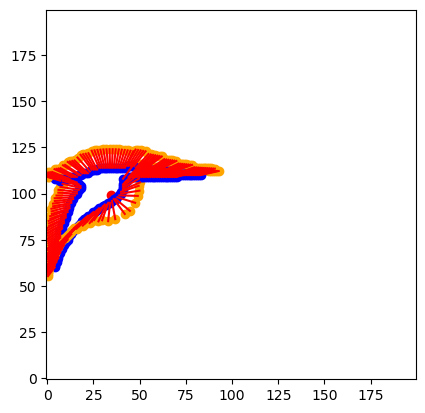

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

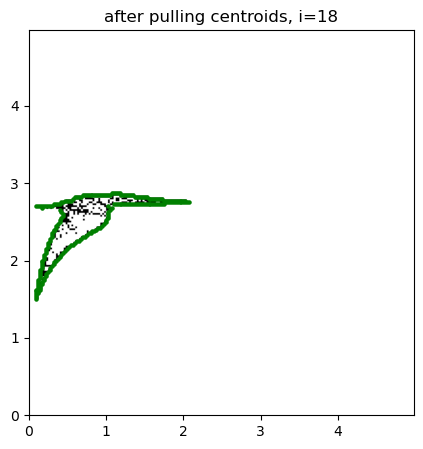

18 1.0.,19,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

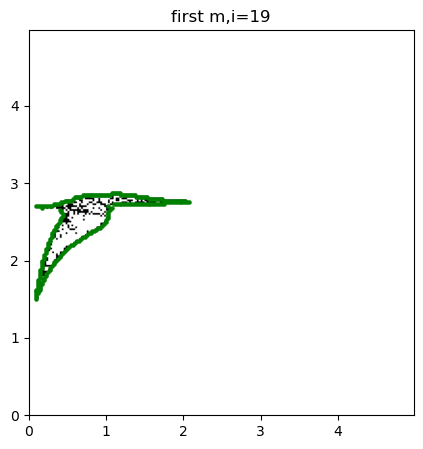

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

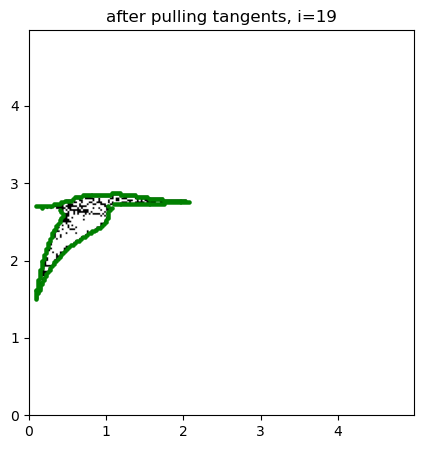

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

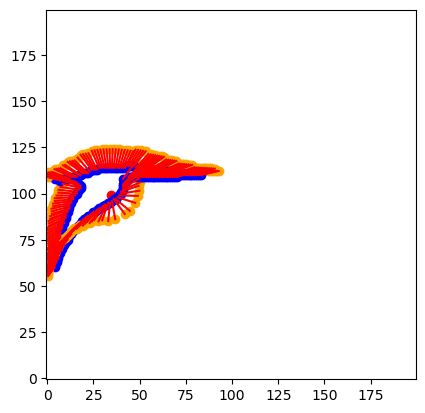

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

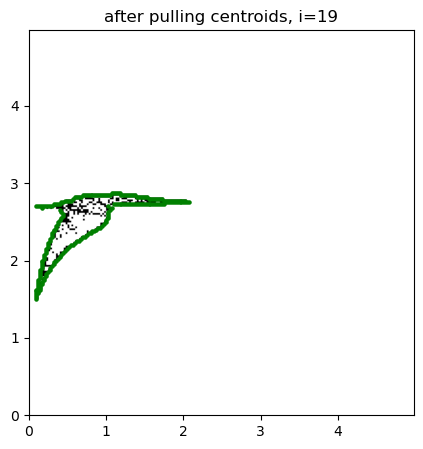

19 2.0.,

In [34]:
#code that runs the boundary exploration in the space given by the function myfN2
#set plotting:False in args dict when running for many iterations, so that no plots are shown
futile_cycle_flux_limit = 0.3
def rate_fn(*params):
    epsilon_midpoint = epsilon_list[np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list_cycle_r) == np.max(J_tot_list_cycle_r))[0][0]]))]
    # alpha_14, alpha_41, epsilon_1, epsilon_2 = params[0]
    # epsilon_1 = np.log10(epsilon_1)
    # epsilon_2 = np.log10(epsilon_2)
    alpha_14, alpha_41, amplitude= params[0]
    amplitude = np.log10(amplitude)
    epsilon_1 = epsilon_midpoint + amplitude
    epsilon_2 = epsilon_midpoint - amplitude
    futile_cycles = [[0,5], [1,6], [2,7], [3,8], [4,9]]
    # futile_cycle_flux = 0
     
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    # i = 0
    # while i < 100:  # Limit the number of iterations
    #     if futile_cycle_flux > allowed_cycles:
    #         break
    #     alpha_14, alpha_41 = np.random.uniform(1e-11, 1e3, 2)
    futile_cycle_flux, _ = cycle_flux_fn(futile_cycles, right_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=max_rate_dummy, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                            alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                            alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                            gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    if futile_cycle_flux > futile_cycle_flux_limit + 0.2 or futile_cycle_flux < futile_cycle_flux_limit - 0.2:
        return None, None
    #     i += 1

    # if i == 100:
    #     # print("Warning: Maximum iterations reached without satisfying the allowed_cycles condition.")
    #     return None, None
    # # print(f"Found suitable alpha_14: {alpha_14}, alpha_41: {alpha_41} after {i} iterations with futile_cycle_flux: {futile_cycle_flux}")
    speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)

    return speed, selectivity

outfolder="test"
if not os.path.isdir(outfolder):
    os.mkdir(outfolder)
name_save="namesave_g20000_sweep"
outfolder_final=outfolder
name='%s_last'%(name_save)


settings=defaultsettings.copy()
# constraints={1:{'target':0,'lt':1},3:{'target':2,'lt':1},5:{'target':4,'lt':1}} #the coefficients in the numerator are at most as large as the corresponding in the denominator

# settings['constraints']=constraints
settings['compute_x_y_f']=rate_fn
settings['npars']=3
# settings['mat'] = np.load(os.path.join(outfolder_final,'mat_namesave_g20000_sweep_6.npy'))
# settings['mat_pars'] = np.load(os.path.join(outfolder_final,'mat_pars_namesave_g20000_sweep_6.npy'))

#Initialise and get first 10 points

BE=BF.BoundaryExplorer(**settings)
BE.get_initial_points(10)

#Extend boundary

args=defaultargs.copy()
args["niters"]=20 #just for testing purposes
args['folder_save']=outfolder
args['name_save']=name_save
BE.extend_boundary(**args)


np.save(os.path.join(outfolder_final,'mat_'+name+'.npy'),BE.mat)
np.save(os.path.join(outfolder_final,'mat_pars_'+name+'.npy'),BE.mat_pars)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

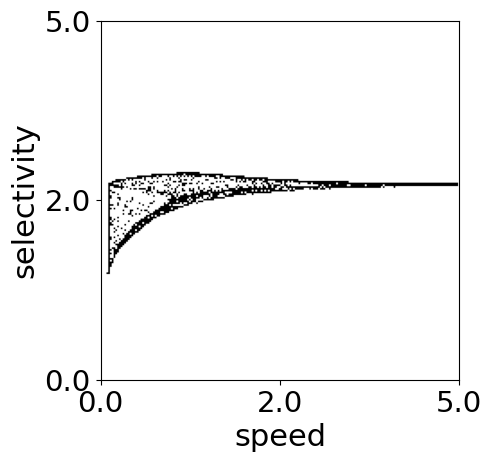

In [33]:
# start coding here
import matplotlib.pyplot as plt
import pickle as pkl
import numpy as np
# pkl.dump(BE, open('BE_kpr.pkl', 'wb'))
plt.rcParams['text.usetex'] = False
plt.subplots(figsize=(5,5))
# with open(snakemake.input[0], 'rb') as handle:
#     BE = pickle.load(handle)
plt.imshow(BE.mat,origin='lower',extent=[1e-11,200,1e-11,200],cmap=plt.cm.Greys)
# plt.title('The dynamic speed-energy tradeoff')
# plt.ylabel(r'energy efficiency $\eta$ [n.d.]')
# plt.xlabel(r'$\bar{q}$ [n.d.]', fontdict={'size': 36})
plt.xlabel(r'speed', fontdict={'size': 22})
plt.ylabel(r'selectivity', fontdict={'size': 22})

# plt.ylabel(r'$\bar{v}$ [n.d.]', fontdict={'size': 36})
# plt.xticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,20,3), 0), fontdict={'size': 24})
# plt.yticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,20,3), 0), fontdict={'size': 24})
plt.xticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,5,3), 0), fontdict={'size': 21})
plt.yticks(np.round(np.linspace(0,200, 3), 0), np.round(np.linspace(0,5,3), 0), fontdict={'size': 21})
# plt.scatter(np.argmin(np.abs(np.arange(0,80, 0.4) - 14.178257380895348)), np.argmin(np.abs(np.arange(0,10, 0.05) - 9.491175296966782)), color='green', s=100, label='Current Point')
# plt.scatter(np.argmin(np.abs(np.arange(0,80, 0.4) - 63.966904915376169)), np.argmin(np.abs(np.arange(0,10, 0.05) - 2.224292566172458)), color='blue', s=100, label='Current Point')
# plt.scatter(np.argmin(np.abs(np.arange(0,80, 0.4) - 0.0015559854903044196)), np.argmin(np.abs(np.arange(0,10, 0.05) - 0.11947555063249195)), color='red', s=100, label='Current Point')


plt.tight_layout()
plt.savefig('output.svg', format='svg', transparent=True)
plt.show()

In [38]:
max_steady_state = np.max(J_tot_list_cycle_r)
def get_best_steady_state(**params):
    return max_steady_state

import numpy as np
import sys, os, time
from utilsGRF import BoundaryFinder as BF

#In all the examples, this will be fixed:

#Define the grid:
stp_ar=np.arange(1e-11, 5,0.025) #The mathematica files to check the results assume a grid spacing of 0.005. Change that if this is modified. 
pos_ar=np.arange(1e-11,5,0.025)

minp=1e-3
maxp=1e3


defaultsettings={'pars_limit':[minp,maxp],
           'row_ar':stp_ar,
          'col_ar':pos_ar,
          'seed':1,
         'mat':None,
         'mat_pars':None}


defaultargs={'niters':5, #for testing purposes only 5 iterations, or it will take very long
      'niters_conv':100,
      'niters_conv_points':1000,
      'niters_save':2,
      'prob_par':0.5,
      'prob_replace':0.5,
      'extr_uniform':[-1,1],
      'L_project':10,
      'plotting':True,
      'verbose':True,
       'dofirstmutate':True,
      'dopullcentroids':True,
      'dopulltangents':True} 

0,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

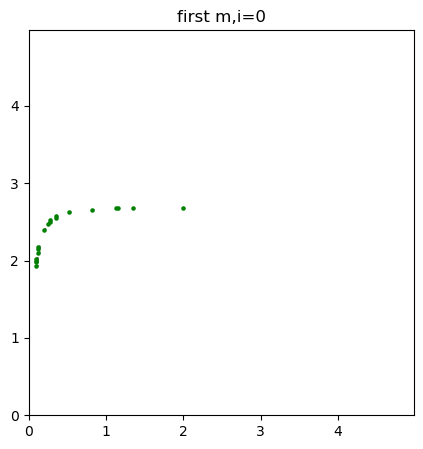

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

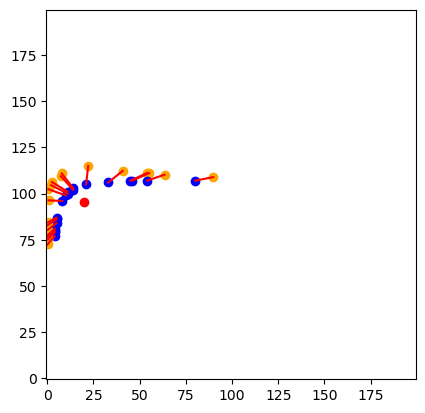

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

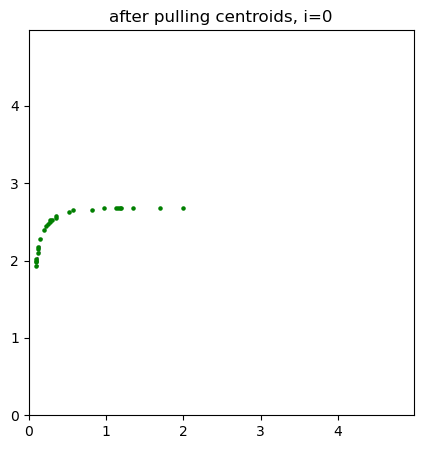

0 17.0.,1,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

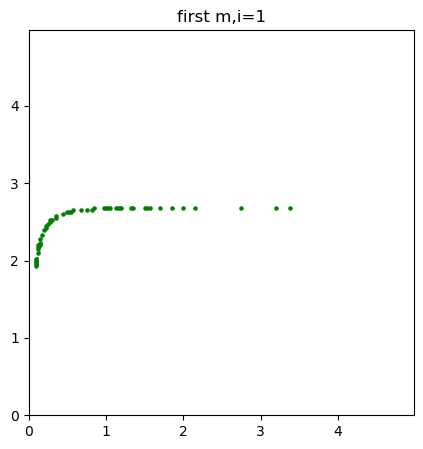

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

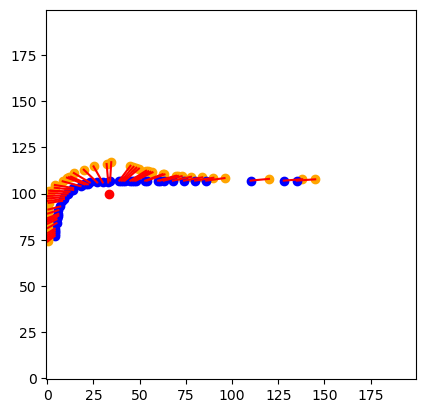

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

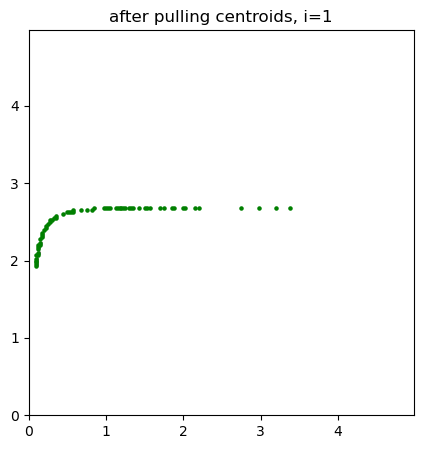

1 39.0.,2,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

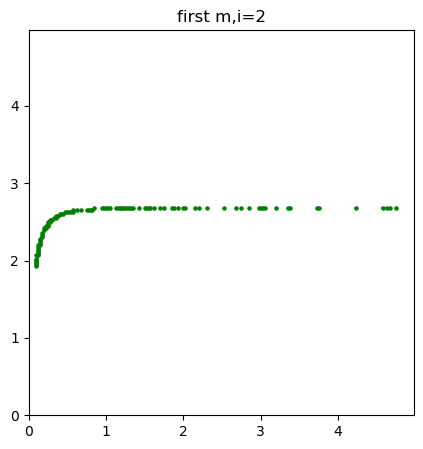

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

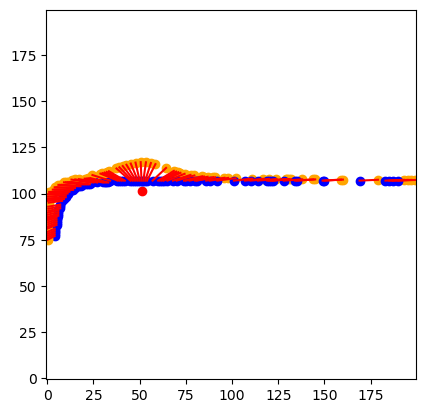

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

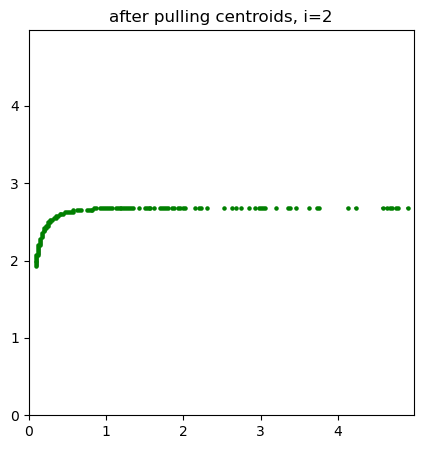

2 51.0.,3,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

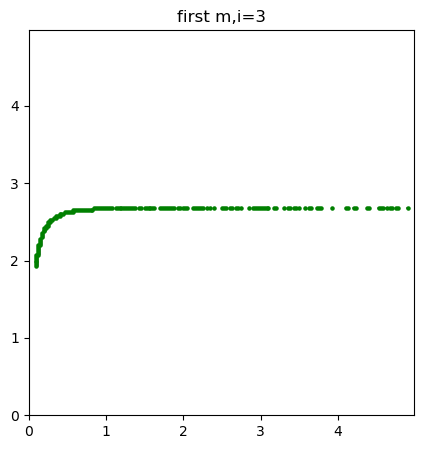

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

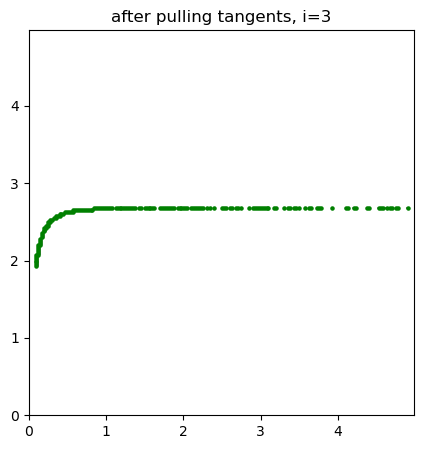

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

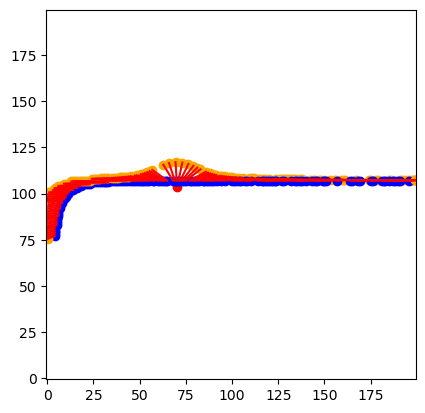

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

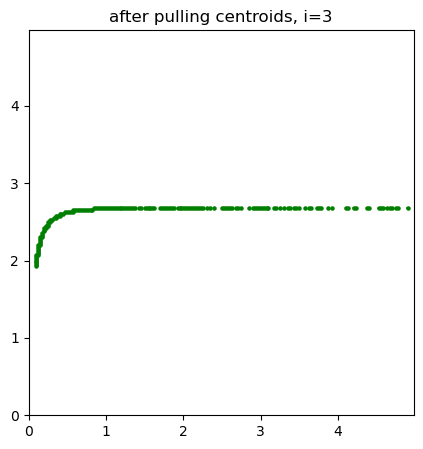

3 45.0.,4,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

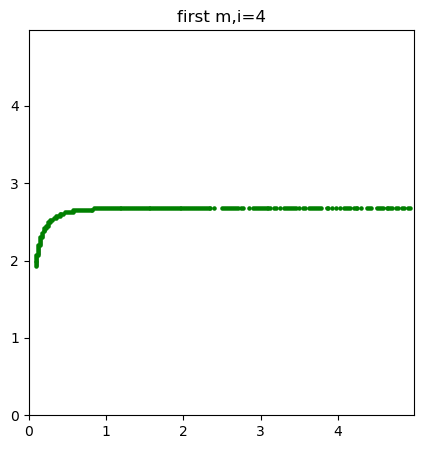

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

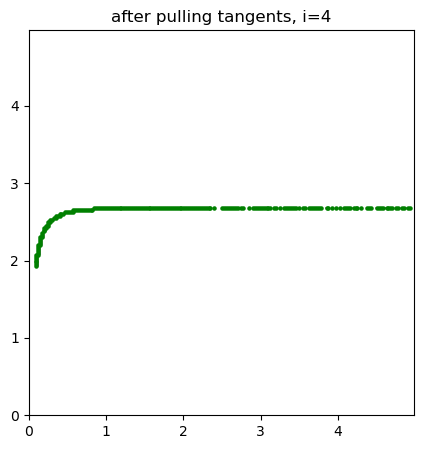

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

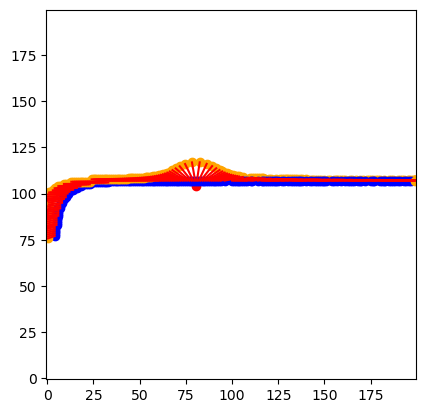

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

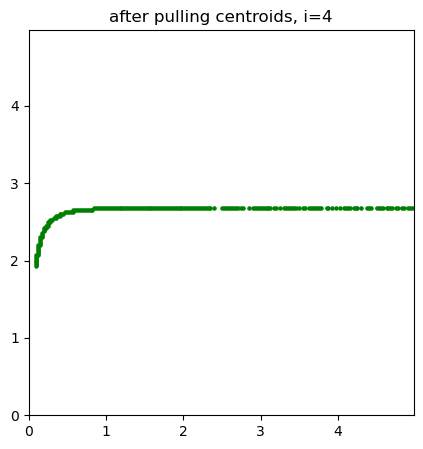

4 29.0.,5,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

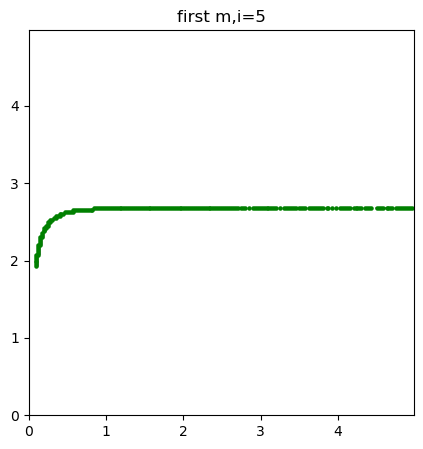

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

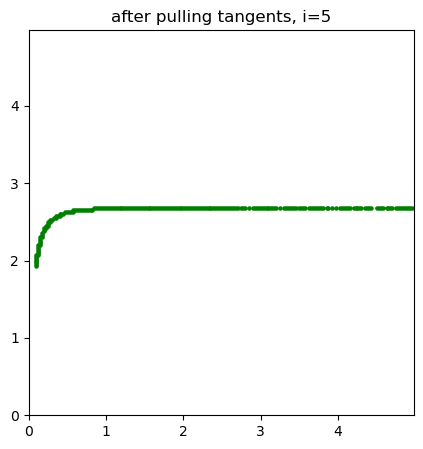

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

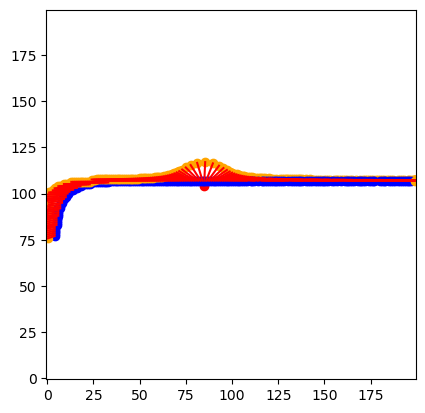

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

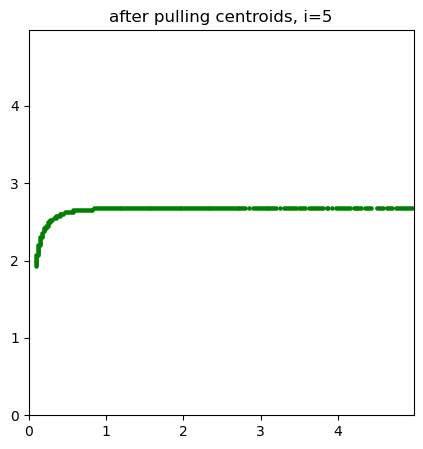

5 15.0.,6,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

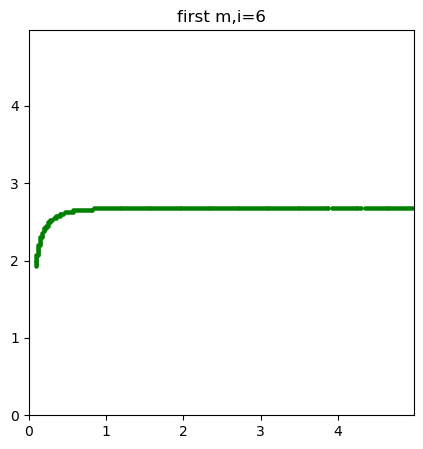

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

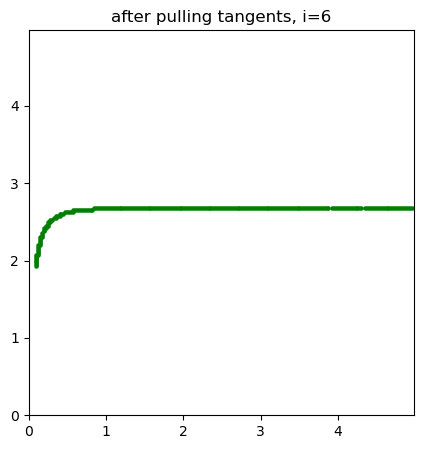

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

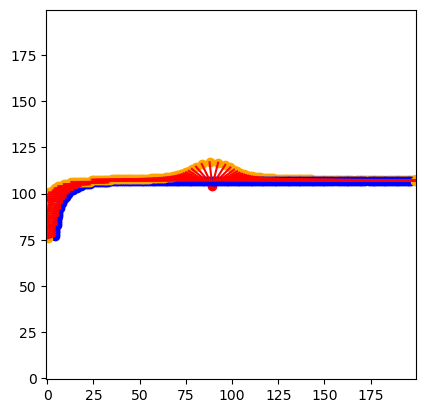

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

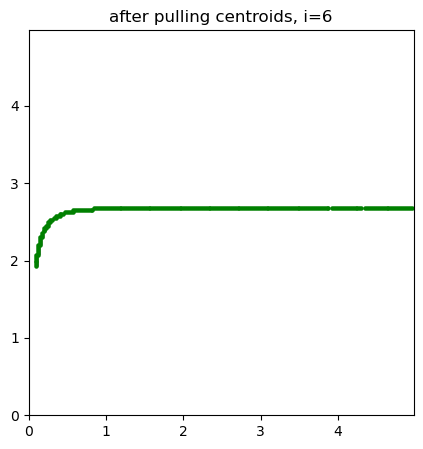

6 13.0.,7,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

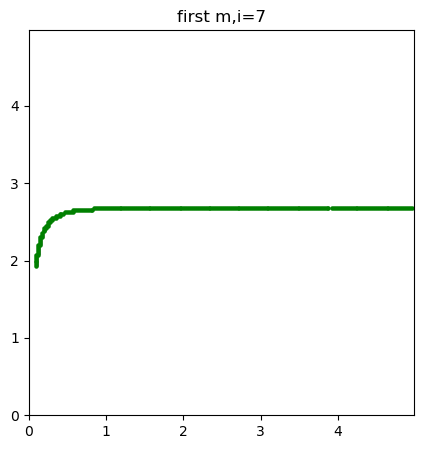

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

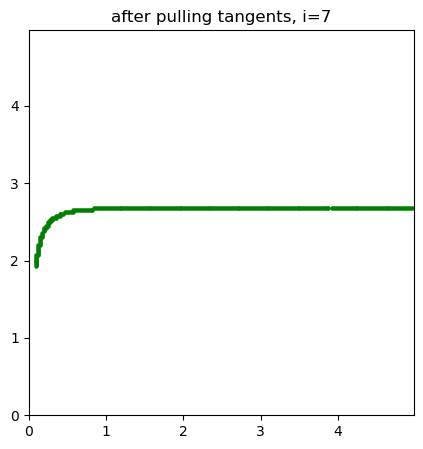

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

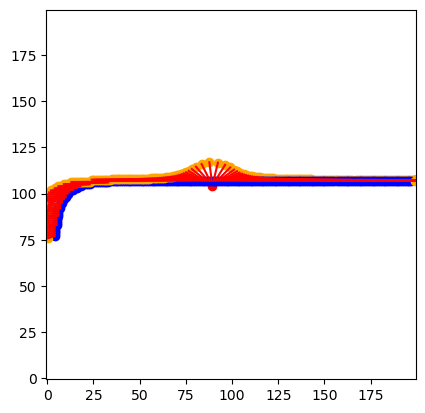

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

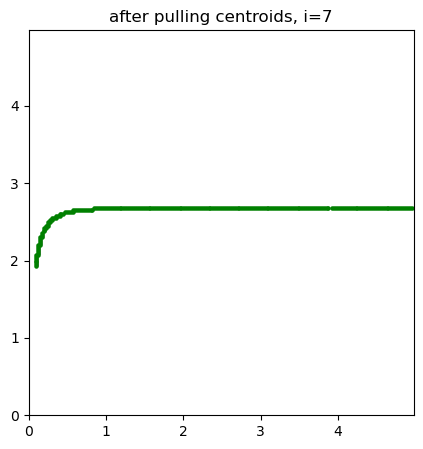

7 2.0.,8,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

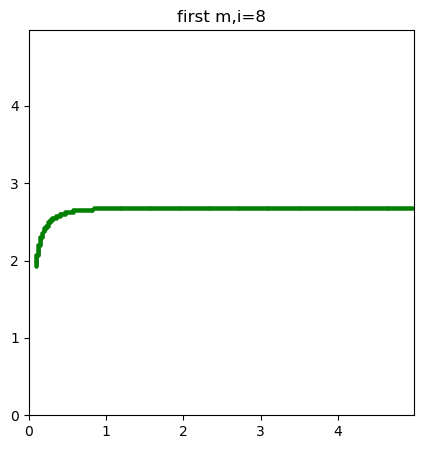

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

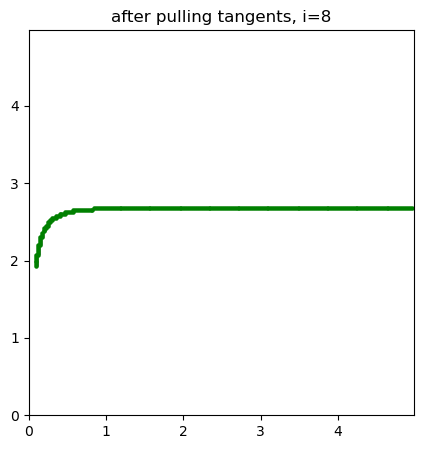

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

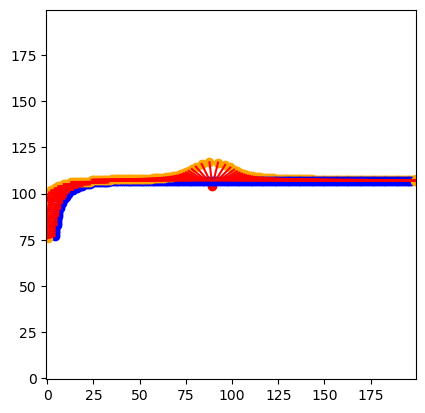

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

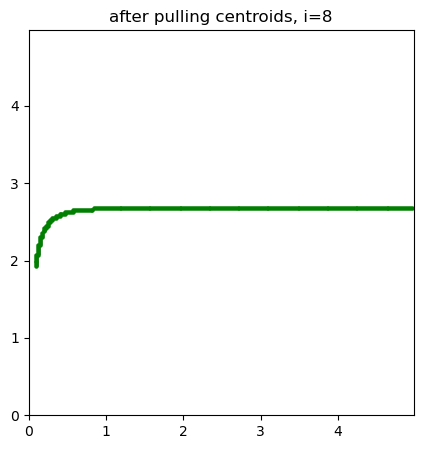

8 2.0.,9,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

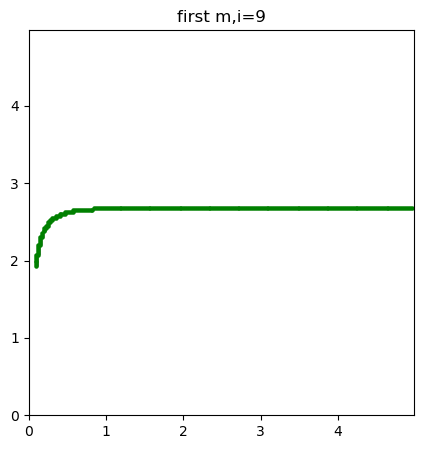

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

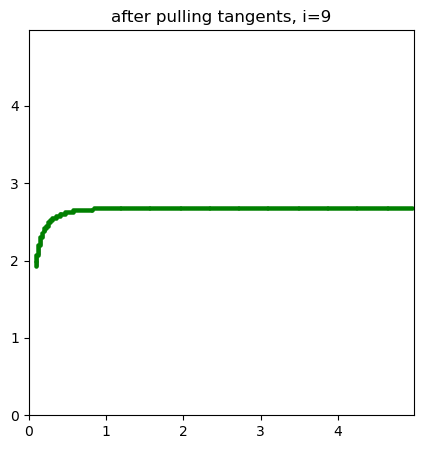

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

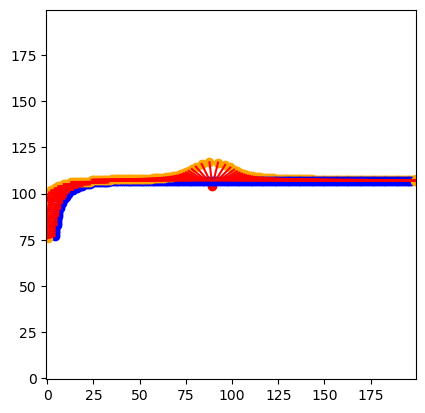

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

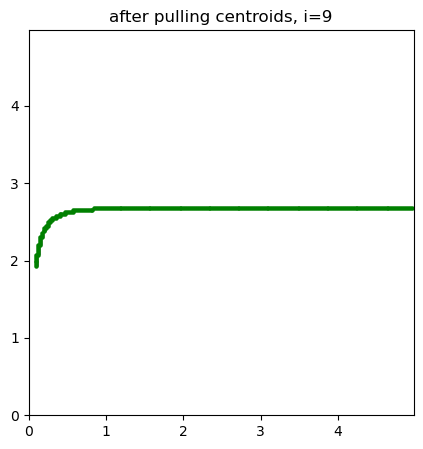

9 0.0.,10,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

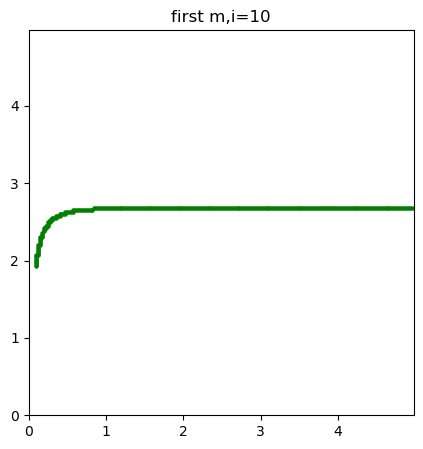

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

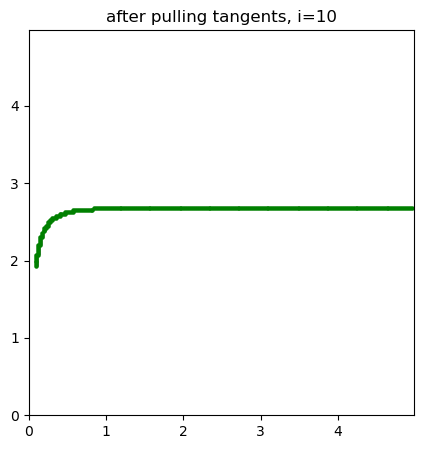

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

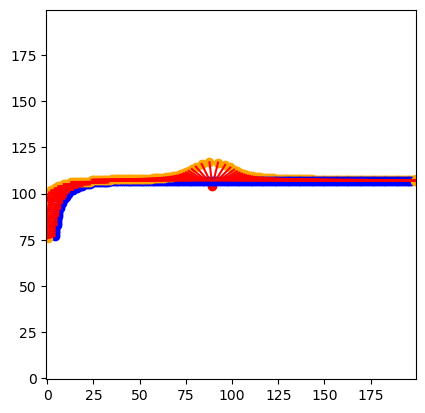

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

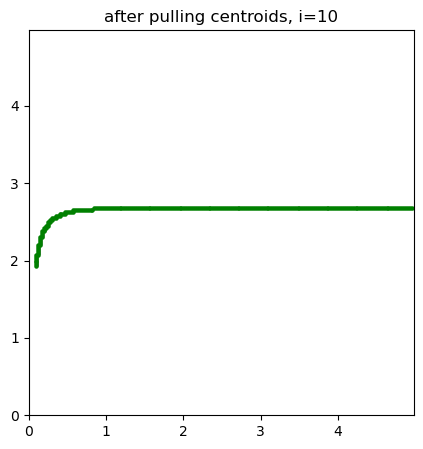

10 1.0.,11,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

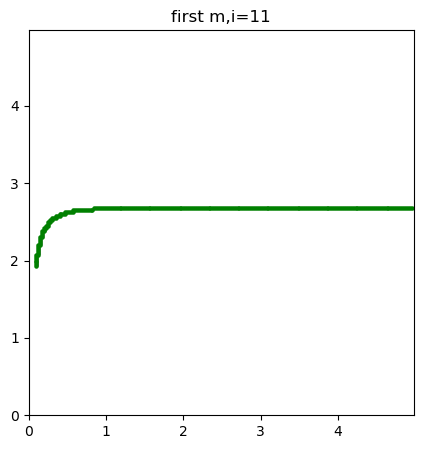

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

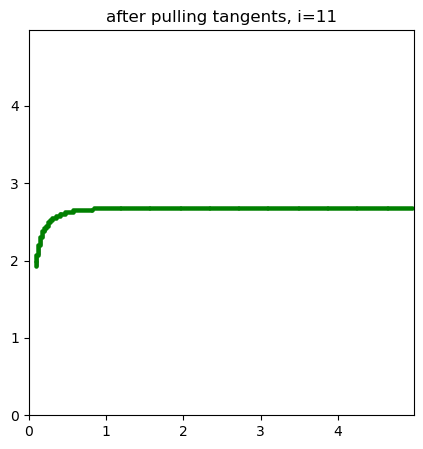

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

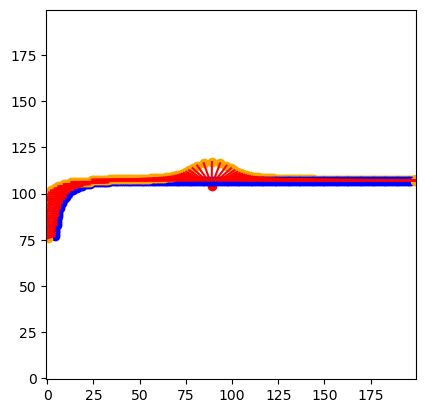

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

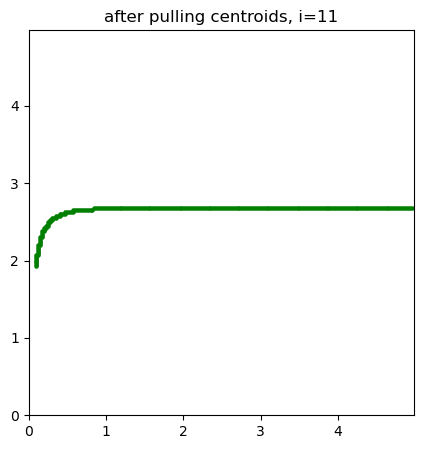

11 0.0.,12,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

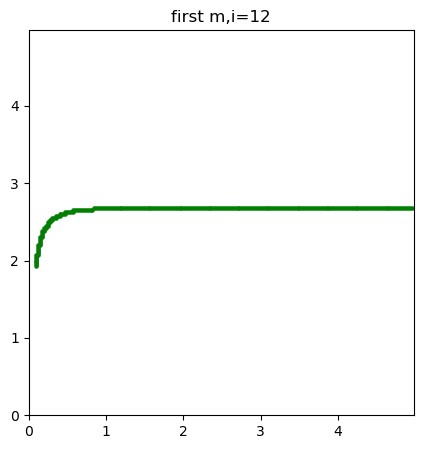

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

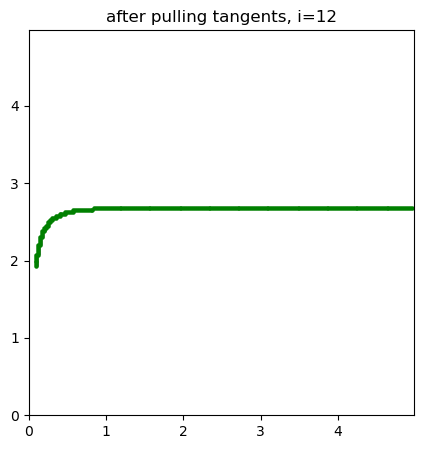

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

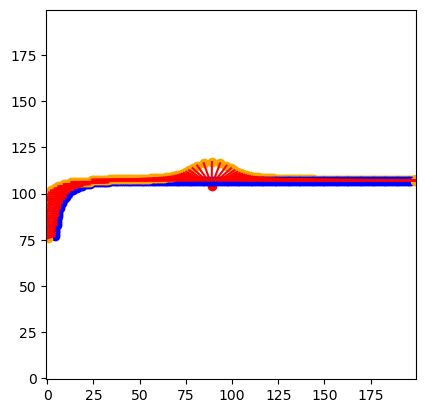

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

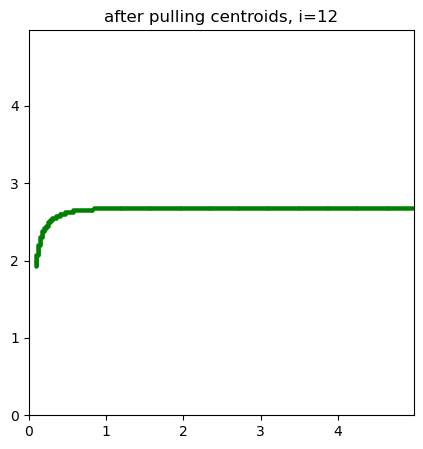

12 0.0.,13,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

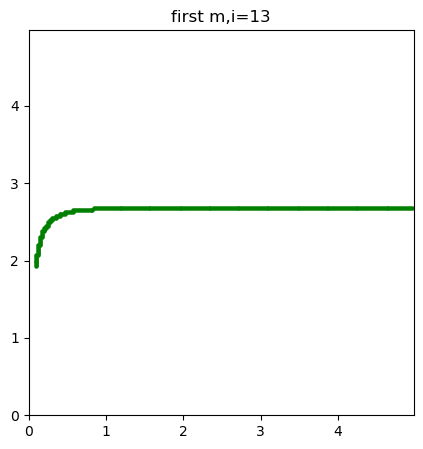

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

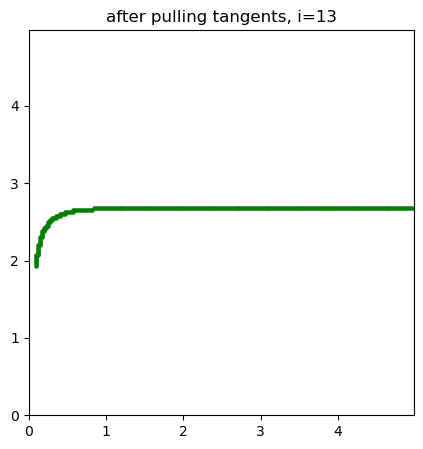

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

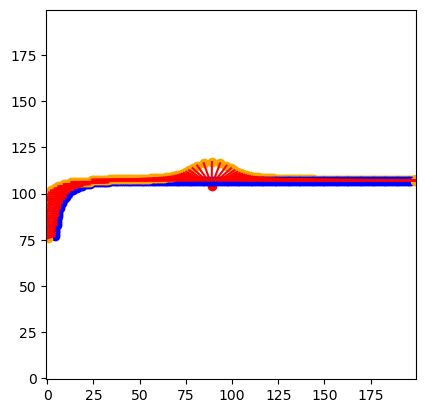

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

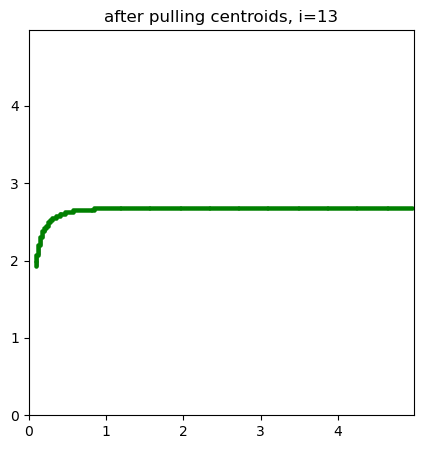

13 1.0.,14,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

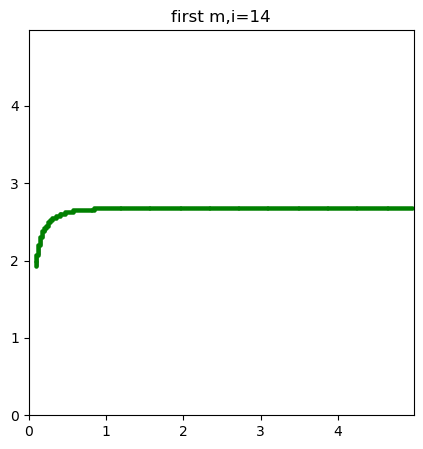

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

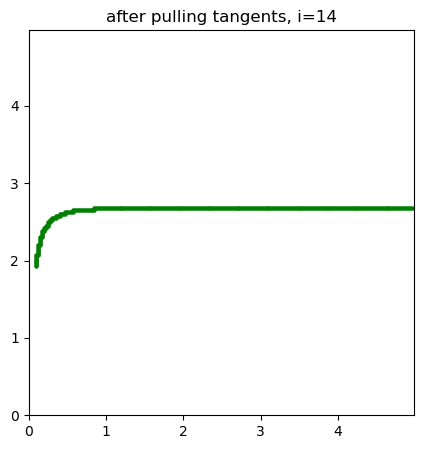

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

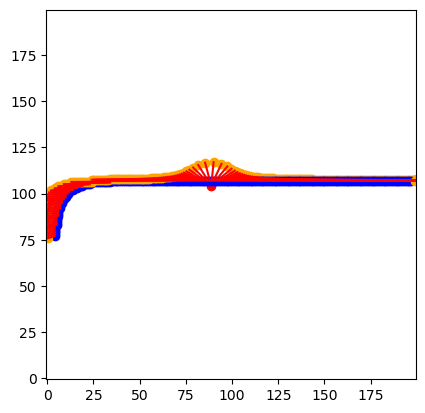

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

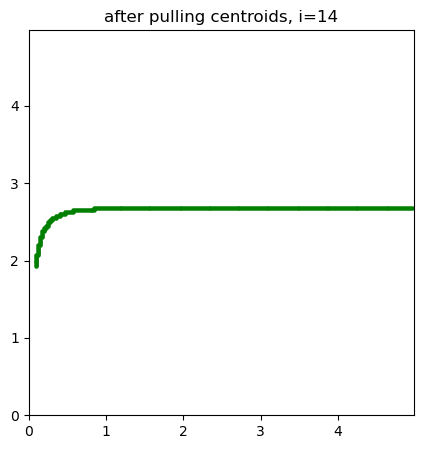

14 0.0.,15,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

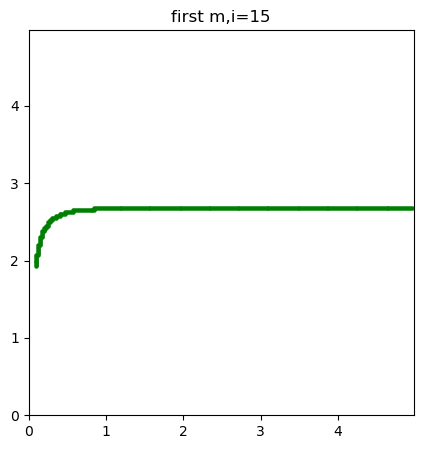

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

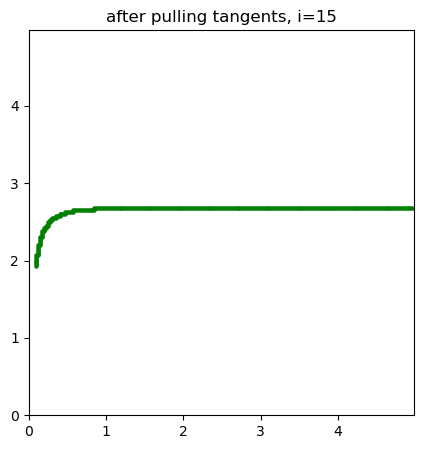

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

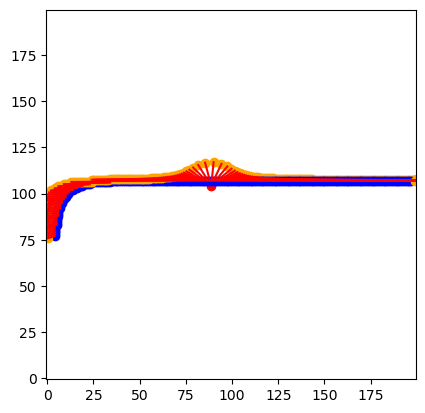

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

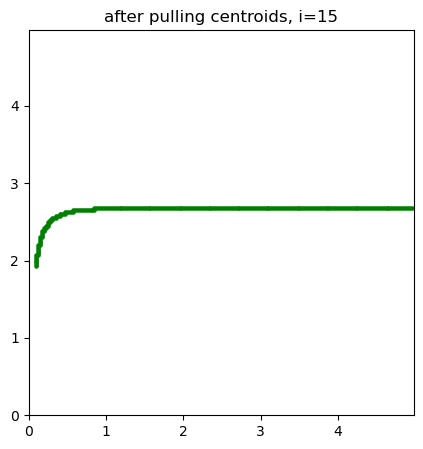

15 0.0.,16,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

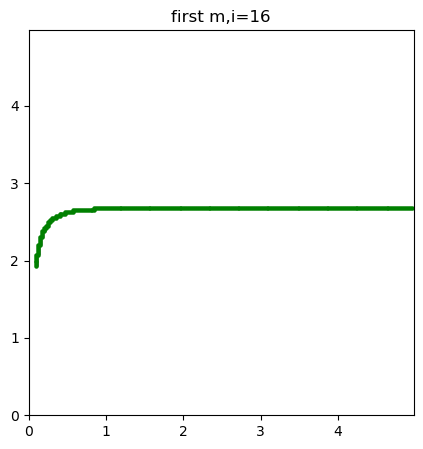

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

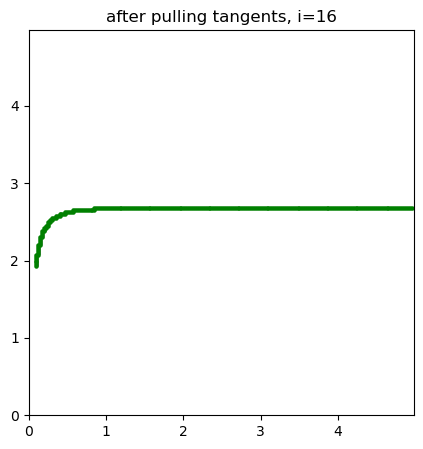

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

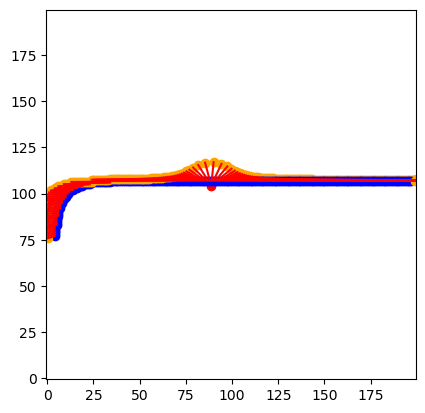

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

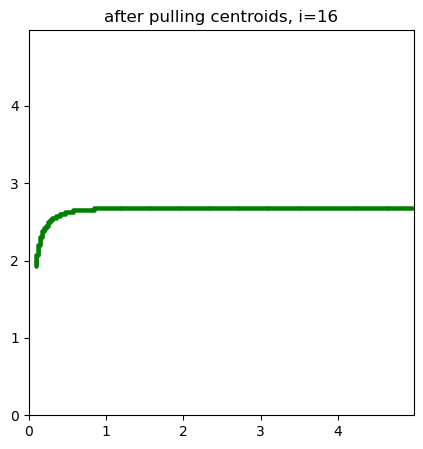

16 0.0.,17,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

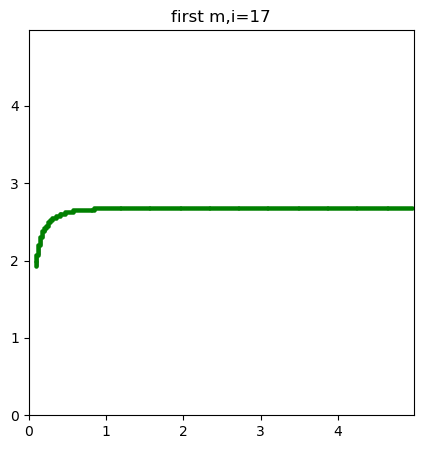

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

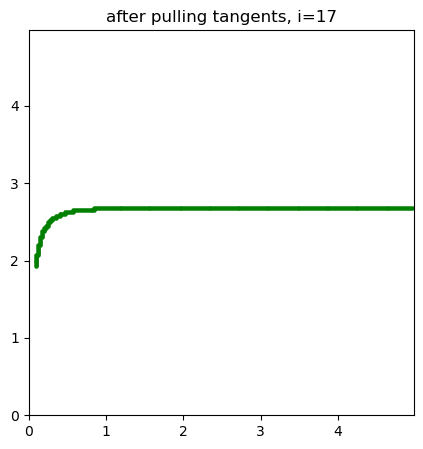

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

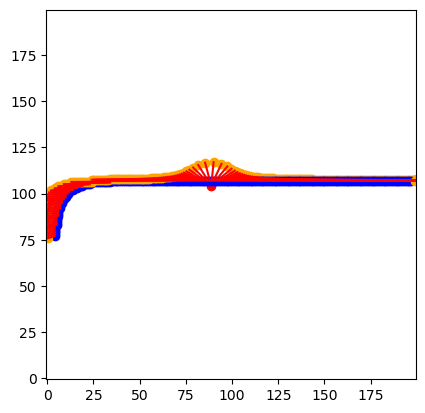

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

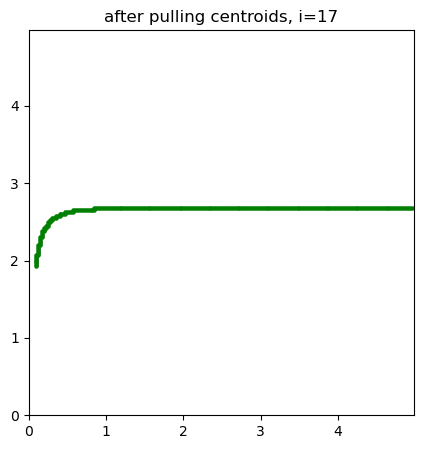

17 0.0.,18,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

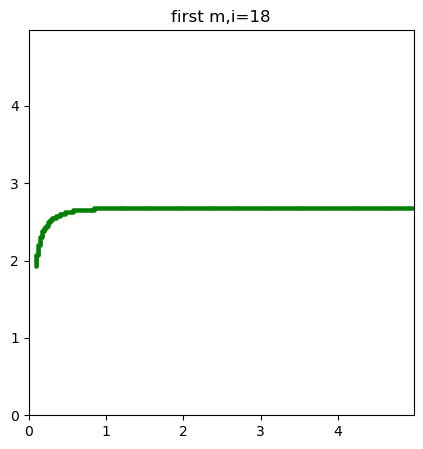

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

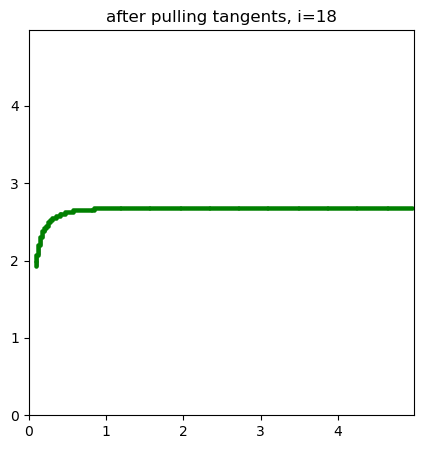

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

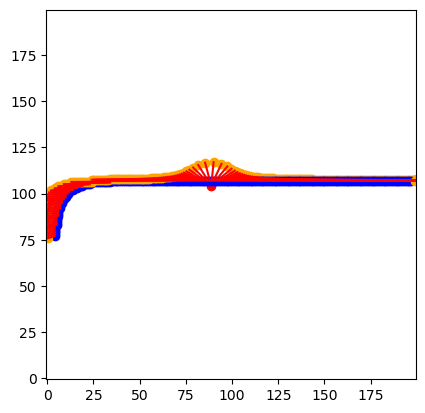

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

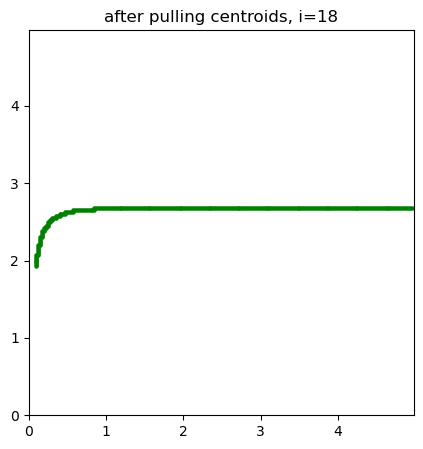

18 0.0.,19,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

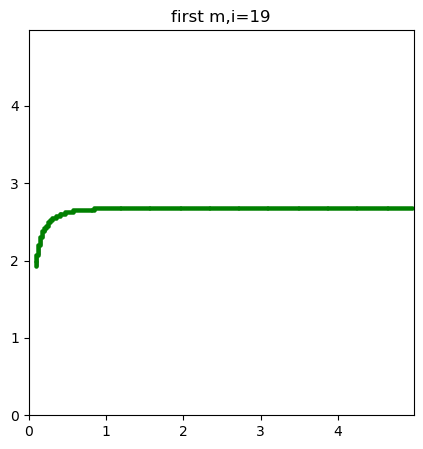

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

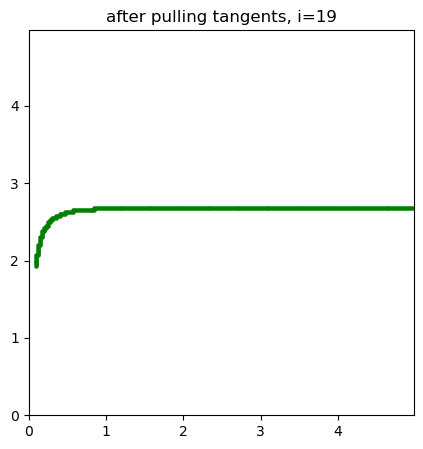

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

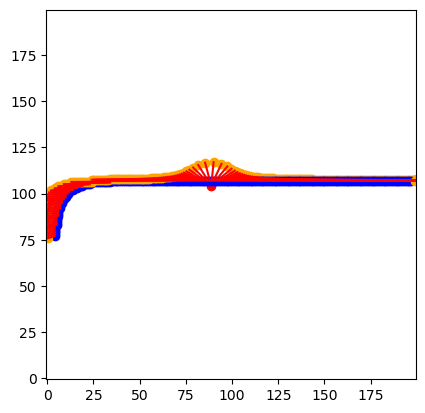

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

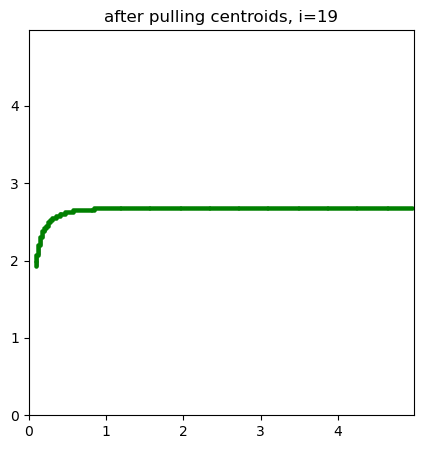

19 0.0.,

In [39]:
#code that runs the boundary exploration in the space given by the function myfN2
#set plotting:False in args dict when running for many iterations, so that no plots are shown
def rate_fn(*params):
    epsilon_midpoint = epsilon_list[np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list_cycle_r) == np.max(J_tot_list_cycle_r))[0][0]]))]
    # alpha_14, alpha_41, epsilon_1, epsilon_2 = params[0]
    # epsilon_1 = np.log10(epsilon_1)
    # epsilon_2 = np.log10(epsilon_2)
    alpha_14 = params[0]
    alpha_41 = alpha_14
    # amplitude = np.log10(amplitude)
    epsilon_1 = epsilon_midpoint - 3
    epsilon_2 = epsilon_midpoint + 3
    # futile_cycles = [[0,5], [1,6], [2,7], [3,8], [4,9]]
    # futile_cycle_flux = 0
     
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    # i = 0
    # while i < 100:  # Limit the number of iterations
    #     if futile_cycle_flux > allowed_cycles:
    #         break
    #     alpha_14, alpha_41 = np.random.uniform(1e-11, 1e3, 2)
    #     futile_cycle_flux, _ = cycle_flux_fn(futile_cycles, right_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=max_rate_dummy, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
    #                                           alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
    #                                           alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
    #                                           gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    
    #     i += 1

    # if i == 100:
    #     # print("Warning: Maximum iterations reached without satisfying the allowed_cycles condition.")
    #     return None, None
    # # print(f"Found suitable alpha_14: {alpha_14}, alpha_41: {alpha_41} after {i} iterations with futile_cycle_flux: {futile_cycle_flux}")
    speed, selectivity = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    return speed, selectivity

outfolder="test"
if not os.path.isdir(outfolder):
    os.mkdir(outfolder)
name_save="namesave_g20000_sweep"
outfolder_final=outfolder
name='%s_last'%(name_save)


settings=defaultsettings.copy()
# constraints={1:{'target':0,'lt':1},3:{'target':2,'lt':1},5:{'target':4,'lt':1}} #the coefficients in the numerator are at most as large as the corresponding in the denominator

# settings['constraints']=constraints
settings['compute_x_y_f']=rate_fn
settings['npars']=1
# settings['mat'] = np.load(os.path.join(outfolder_final,'mat_namesave_g20000_sweep_6.npy'))
# settings['mat_pars'] = np.load(os.path.join(outfolder_final,'mat_pars_namesave_g20000_sweep_6.npy'))

#Initialise and get first 10 points

BE=BF.BoundaryExplorer(**settings)
BE.get_initial_points(10)

#Extend boundary

args=defaultargs.copy()
args["niters"]=20 #just for testing purposes
args['folder_save']=outfolder
args['name_save']=name_save
BE.extend_boundary(**args)


np.save(os.path.join(outfolder_final,'mat_'+name+'.npy'),BE.mat)
np.save(os.path.join(outfolder_final,'mat_pars_'+name+'.npy'),BE.mat_pars)

In [5]:
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from dynamic_catalysis_model import max_rate_six_states, cycle_flux_fn, osc_midpoint_six_states, map_graph_weights_six_states

import mpmath
import numpy as np
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact
import mpmath as mp
from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
from bokeh.models import MathML
import pickle as pkl
import networkx as nx
output_notebook()


def heatmap(F1, F2, oscMidpoint, amplitude):
    turnover_fold_increase = np.zeros(F1.shape)
    selectivity = np.zeros(F1.shape)
    for i in range(F1.shape[0]):
        for j in range(F1.shape[1]):
            epsilon_1 = float(oscMidpoint + amplitude)
            epsilon_2 = float(oscMidpoint - amplitude)

            alpha_14 = F1[i, j]
            alpha_41 = F2[i, j] 

            right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
            wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
            J_turnover, J_futile = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                    alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                    alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                    gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
        
            turnover_fold_increase[i, j] = J_turnover
            selectivity[i, j] = J_futile 
    return turnover_fold_increase, selectivity

Loading BokehJS ...

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family ['Lucida Sans'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida

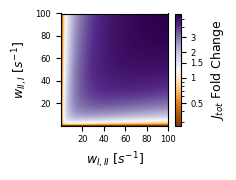

In [8]:
class MidPointLogNorm(LogNorm):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        LogNorm.__init__(self,vmin=vmin, vmax=vmax, clip=clip)
        self.midpoint=midpoint
    def __call__(self, value, clip=None):
        # I'm ignoring masked values and all kinds of edge cases to make a
        # simple example...
        x, y = [np.log(self.vmin), np.log(self.midpoint), np.log(self.vmax)], [0, 0.5, 1]
        return np.ma.masked_array(np.interp(np.log(value), x, y))

max_frequency=100
n_points=100

frequencies_1 = np.linspace(1e-5, max_frequency, n_points)
frequencies_2 = np.linspace(1e-5, max_frequency, n_points)
amplitude = 2
oscMidpoint = epsilon_list[np.where(np.array(J_tot_list_cycle_r) == np.max(J_tot_list_cycle_r))[0][0]]


palette = brewer['PuOr'][11][::-1]
palette = bokeh.palettes.interp_palette(palette, 400)

F1, F2 = np.meshgrid(frequencies_1, frequencies_2)
turnover_fold_increase, selectivity = heatmap(F1, F2, oscMidpoint, amplitude)
bound = np.min([np.abs(np.max(np.log10(turnover_fold_increase))), np.abs(np.min(np.log10(turnover_fold_increase)))])

cmap = LinearSegmentedColormap.from_list('mycmap', palette)
plt.figure(figsize=(2.4, 1.9))
plt.imshow(turnover_fold_increase, extent=(1e-5, max_frequency, 1e-5, max_frequency), norm=MidPointLogNorm(vmin=np.min(turnover_fold_increase), vmax=np.max(turnover_fold_increase), midpoint=1), origin='lower', aspect='auto', cmap=cmap)
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.xticks([20, 40, 60, 80, 100], fontsize=6)
plt.yticks([20, 40, 60, 80, 100], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
cbar = plt.colorbar(label='$J_{tot}$ Fold Change')
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
cbar.set_ticks([0.5, 1, 1.5, 2, 3])
cbar.set_ticklabels([0.5, 1, 1.5, 2, 3], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
plt.tight_layout()

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.


findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: 

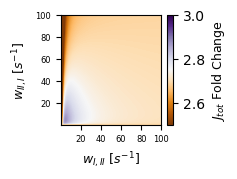

In [9]:
import matplotlib as mpl
cmap = LinearSegmentedColormap.from_list('mycmap', palette)
plt.figure(figsize=(2.4, 1.9))
plt.imshow(selectivity, extent=(1e-5, max_frequency, 1e-5, max_frequency), norm=mpl.colors.Normalize(vmin=2.5, vmax=3), origin='lower', aspect='auto', cmap=cmap)
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.xticks([20, 40, 60, 80, 100], fontsize=6)
plt.yticks([20, 40, 60, 80, 100], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
cbar = plt.colorbar(label='$J_{tot}$ Fold Change')
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
# cbar.set_ticks([0.5, 1, 1.5, 2, 3])
# cbar.set_ticklabels([0.5, 1, 1.5, 2, 3], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
plt.tight_layout()